# 11 — Curved interfaces: local orders, lenses, spheres and internal returns

When a plane wave meets a curved surface, ordinary Fresnel reflection and
transmission treat the surface as locally flat. That is **order 0**. The local
expansion used here adds curvature corrections of increasing order in
1/(kR), where R is the local radius of curvature:

$$
E = e^{ik_0 S}\sum_{m=0}^{N} \frac{A_m}{(ik_0)^m},
$$

with the amplitudes $A_m$ generated from the eikonal, transport and
divergence equations at the interface. **Order 3** keeps $m \le 3$.

This notebook answers five questions, in this order:

1. **Is the expansion right?** Orders 0–3 against exact single-interface
   Maxwell fields.
2. **Where does it apply?** The incidence angles at which the series still
   converges.
3. **When is our lens model itself reliable?** BEM checked against Mie, and our
   single-pass model against BEM as the lens thickness changes.
4. **Does order 3 change what a lens does?** Four thin curved 6λ₀ lenses, order
   0 versus order 3, against BEM of the whole lens, with a Stratton–Chu check of
   our own propagation.
5. **Does a better interface field give a better propagated field?** A glass
   sphere under a Gaussian beam, with every internal return, against the exact
   Debye terms and Lorenz–Mie.

| Method | What it computes | Role here |
|---|---|---|
| **Ours, order 0** | Exact Fresnel of every incident plane wave on the local tangent plane of every surface point | Default interaction |
| **Ours, order 3** | Order 0 plus three curvature corrections, applied only where the series converges | Candidate refinement |
| **Exact single interface** | Bessel/Hankel partial waves for one curved interface (first Debye term) | Exact reference for the local expansion |
| **BEM** | PMCHWT boundary integrals of the whole lens: both faces, rim and internal returns | Full-wave reference for lenses |
| **Mie / Debye** | Multipole solution of the sphere, split into its Debye terms (one term per internal return) | Exact reference for the sphere and each return |
| **Ours, with returns** | T and R at every encounter; the reflected part is carried back inside and met again | Operational Debye series |
| **Stratton–Chu** | Radiation integral of our own exit-face field | Independent check of our surface-to-plane step |

Conventions: λ₀ = 532 nm, glass n = 1.5 in air, unit x-polarized plane wave
along +z. Complex fields are compared as they are, with no gain, phase or focal
alignment. Intensity maps use the hot palette with their own physical
colorbars; compare amplitudes with the colorbar values and line profiles.
Lens edges do not cut the field: light passing outside a lens is kept
([surface edges and pupils](../../../docs/PUPILS_AND_EDGES.md)).

In [1]:
%matplotlib inline
import html
import json
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import vecdiff_general as optics
from IPython.display import HTML, Markdown, display
from matplotlib.colors import Normalize
from vecdiff_general.media.medium import Z0
from vecdiff_general.propagation.experiments.polar_lens import (
    canonical_values,
    convergent_incidence,
    series_ratio,
)
from vecdiff_general.propagation.experiments.taylor_interface import interface_expansion
from vecdiff_general.propagation.references.debye import (
    cylinder_single_interface,
    sphere_single_interface,
)

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "general").is_dir())
sys.path.insert(0, str(ROOT / "general/examples"))
import curved_interfaces_study as study  # noqa: E402

WAVELENGTH = study.WAVELENGTH
ORDER_COLORS = {0: "#1f77b4", 1: "#2ca02c", 2: "#9467bd", 3: "#ff7f0e"}
plt.rcParams.update({"figure.dpi": 150, "axes.grid": False, "font.size": 9})
started = perf_counter()


def table(rows, columns):
    # Theme-neutral HTML table; each column header names its quantity.
    parts = [
        '<div style="max-width:100%;overflow-x:auto;color:inherit">',
        '<table style="border-collapse:collapse;font-size:13px;color:inherit;background:transparent">',
        '<thead><tr style="background:rgba(127,127,127,.18);color:inherit">',
    ]
    parts += [
        f'<th style="padding:8px;text-align:left;border-bottom:2px solid rgba(127,127,127,.65)">{html.escape(label)}</th>'
        for _, label, _ in columns
    ]
    parts.append("</tr></thead><tbody>")
    for i, row in enumerate(rows):
        shade = "rgba(127,127,127,.10)" if i % 2 else "transparent"
        parts.append(f'<tr style="background:{shade}">')
        for key, _, fmt in columns:
            value = row.get(key)
            text = "—" if value is None else (fmt.format(value) if fmt else str(value))
            parts.append(
                f'<td style="padding:8px;border-bottom:1px solid rgba(127,127,127,.3)">{html.escape(text)}</td>'
            )
        parts.append("</tr>")
    parts.append("</tbody></table></div>")
    display(HTML("".join(parts)))


print(
    f"λ₀ = {WAVELENGTH * 1e9:g} nm, n = {study.INDEX}, lens diameter = {study.DIAMETER:g} λ₀"
)

λ₀ = 532 nm, n = 1.5, lens diameter = 6 λ₀


## 1 · Is the expansion right? Orders 0–3 against exact fields

A single curved interface has an exact solution: the partial-wave field of a
plane wave meeting one dielectric cylinder or sphere, with no internal return
(the first Debye term). Near the illuminated vertex, its expansion in 1/(kR)
must match the local recurrence order by order. If the coefficients are right,
the error through order N falls as $(kR)^{-(N+1)}$: each doubling of kR divides
the order-0 error by 2 and the order-3 error by 16.

Below, E and Z₀H are compared at five surface points up to 0.3R from the
vertex (incidence up to 21°), for a wave going from air into glass.

exact references: 2.2 s


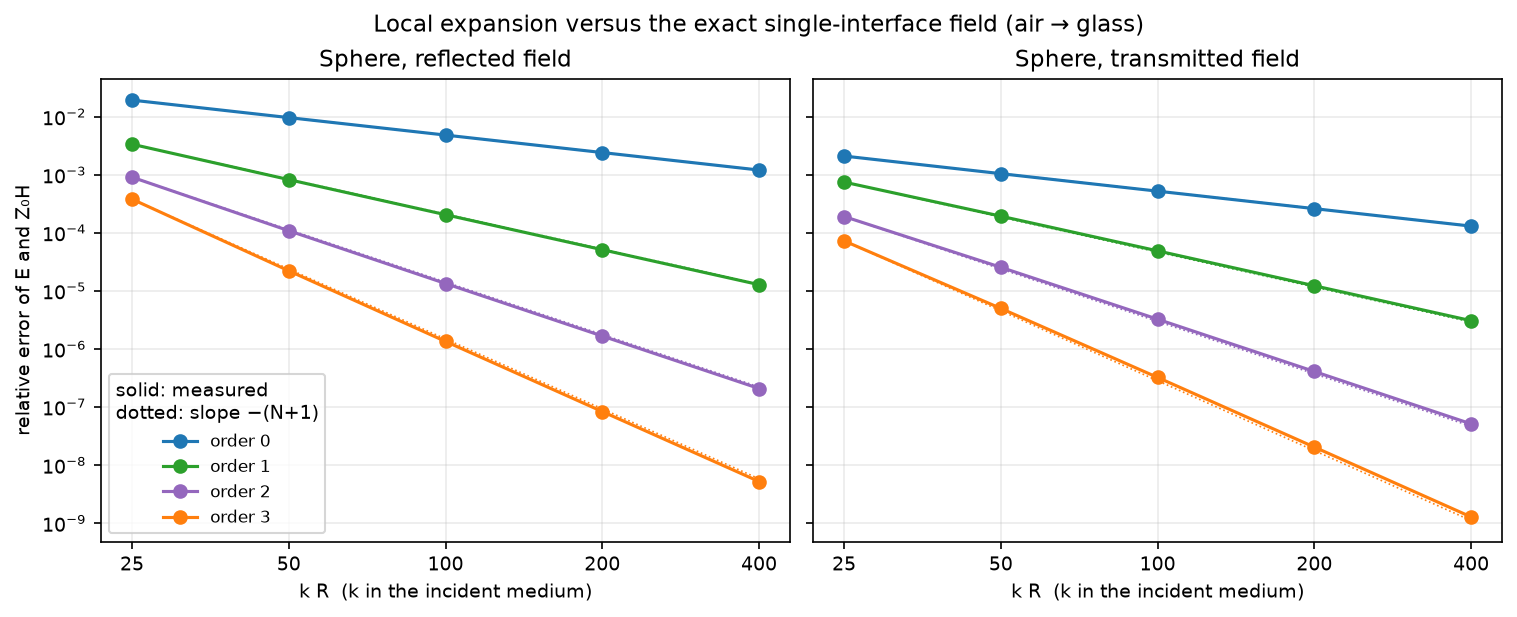

Geometry,Field,"Error at kR = 200, order 0","Error at kR = 200, order 3","Error ratio kR 100→200, order 0 (expect 2)",… order 1 (expect 4),… order 2 (expect 8),… order 3 (expect 16)
"sphere, convex toward the wave",reflected,2.41e-03,8.36e-08,2.00,4.01,8.03,16.13
"sphere, convex toward the wave",transmitted,2.61e-04,2.04e-08,2.00,3.99,7.95,15.83
"sphere, concave toward the wave",reflected,2.41e-03,8.36e-08,2.00,4.01,8.03,16.13
"sphere, concave toward the wave",transmitted,2.61e-04,2.04e-08,2.00,3.99,7.95,15.83
"cylinder, TE",reflected,3.69e-03,4.57e-08,2.00,4.01,8.03,16.14
"cylinder, TE",transmitted,9.56e-04,1.17e-08,2.00,3.99,7.96,15.87
"cylinder, TM",reflected,3.64e-03,1.12e-08,2.00,3.99,7.96,15.89
"cylinder, TM",transmitted,8.27e-04,1.53e-09,2.00,4.00,7.97,15.82


In [2]:
UV = np.array([[0, 0], [0.2, 0.1], [-0.15, 0.25], [0.3, -0.2], [-0.25, -0.05]])
KR = np.array([25, 50, 100, 200, 400])


def exact_errors(kR, body, interior=False, polarization="TE"):
    # Relative error of E and Z0 H through order N, reflected and transmitted.
    radius, sign = kR / (2 * np.pi), (-1 if interior else 1)
    if body == "sphere":
        uv, amplitude = UV, (1, 0, 0)
        height = lambda u, v: sign * (1 - (1 - u * u - v * v) ** 0.5)  # noqa: E731
    else:
        uv = np.column_stack((np.linspace(-0.3, 0.3, 7), np.zeros(7)))
        amplitude = (0, 1, 0) if polarization == "TE" else (1, 0, 0)
        height = lambda u, v: sign * (1 - (1 - u * u) ** 0.5)  # noqa: E731
    local = interface_expansion(
        height,
        uv * radius,
        n_incident=1.0,
        n_transmitted=1.5,
        direction=(0, 0, 1),
        amplitude=amplitude,
        order=3,
        length_scale=radius,
    )
    if body == "sphere":
        exact = sphere_single_interface(
            local.points, 1.0, radius, 1.0, 1.5, interior=interior
        )
    else:
        exact = cylinder_single_interface(
            local.points, 1.0, radius, 1.0, 1.5, polarization
        )
    out = {}
    for branch in ("reflected", "transmitted"):
        e, h = exact[branch]
        scale = np.sum(abs(e) ** 2 + abs(Z0 * h) ** 2)
        out[branch] = [
            np.sqrt(
                np.sum(
                    abs(t.electric.values - e) ** 2 + abs(Z0 * (t.magnetic - h)) ** 2
                )
                / scale
            )
            for t in (local.trace(branch, 1.0, order=n) for n in range(4))
        ]
    return out


t0 = perf_counter()
cases_exact = {
    "sphere, convex toward the wave": dict(body="sphere"),
    "sphere, concave toward the wave": dict(body="sphere", interior=True),
    "cylinder, TE": dict(body="cylinder", polarization="TE"),
    "cylinder, TM": dict(body="cylinder", polarization="TM"),
}
exact_results = {
    name: [exact_errors(kR, **options) for kR in KR]
    for name, options in cases_exact.items()
}
print(f"exact references: {perf_counter() - t0:.1f} s")

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True, layout="constrained")
for ax, branch in zip(axes, ("reflected", "transmitted")):
    rows = exact_results["sphere, convex toward the wave"]
    for n in range(4):
        values = np.array([r[branch][n] for r in rows])
        ax.loglog(KR, values, "o-", color=ORDER_COLORS[n], label=f"order {n}")
        ax.loglog(
            KR, values[0] * (KR / KR[0]) ** -(n + 1), ":", color=ORDER_COLORS[n], lw=0.8
        )
    ax.set(
        xlabel="k R  (k in the incident medium)",
        title=f"Sphere, {branch} field",
        ylabel="relative error of E and Z₀H" if branch == "reflected" else None,
    )
    ax.set_xticks(KR, [str(v) for v in KR])
    ax.minorticks_off()
    ax.grid(True, which="both", alpha=0.25)
axes[0].legend(title="solid: measured\ndotted: slope −(N+1)", fontsize=8)
fig.suptitle("Local expansion versus the exact single-interface field (air → glass)")
plt.show()

rows = []
for name, results in exact_results.items():
    for branch in ("reflected", "transmitted"):
        e = np.array([r[branch] for r in results])
        rows.append(
            dict(
                case=name,
                branch=branch,
                **{f"e{n}": e[KR == 200][0][n] for n in range(4)},
                **{f"g{n}": e[KR == 100][0][n] / e[KR == 200][0][n] for n in range(4)},
            )
        )
table(
    rows,
    [
        ("case", "Geometry", None),
        ("branch", "Field", None),
        ("e0", "Error at kR = 200, order 0", "{:.2e}"),
        ("e3", "Error at kR = 200, order 3", "{:.2e}"),
        ("g0", "Error ratio kR 100→200, order 0 (expect 2)", "{:.2f}"),
        ("g1", "… order 1 (expect 4)", "{:.2f}"),
        ("g2", "… order 2 (expect 8)", "{:.2f}"),
        ("g3", "… order 3 (expect 16)", "{:.2f}"),
    ],
)

Every geometry and polarization shows the asymptotic rate, so the order 1–3
coefficients are those of a true Maxwell solution. The same coefficients were
also generated by a second, independently written recurrence and agree to
3·10⁻¹⁵ (see [the curvature-order study](../../../docs/CURVATURE_ORDERS.md)).

For light leaving glass into air (n₁ > n₂), the exact sphere or cylinder field
also contains a critical-angle wave launched from the ring where incidence is
critical. That wave is not local to the vertex, so this reference cannot isolate
the expansion there; the recurrence itself is index-symmetric.

## 2 · Where does the expansion apply? Convergence of the series

The expansion is asymptotic. Its terms shrink with order only while
$k R \cos^3\theta_t$ stays large; approaching the critical angle, higher terms
grow and adding them makes the field worse. We therefore keep the curvature
corrections only where each retained term is at most half the one before
(optimal truncation); elsewhere the interaction stays at order 0.

The curves show that largest term ratio against incidence angle for a sphere
of radius R, for a glass → air exit and an air → glass entrance.

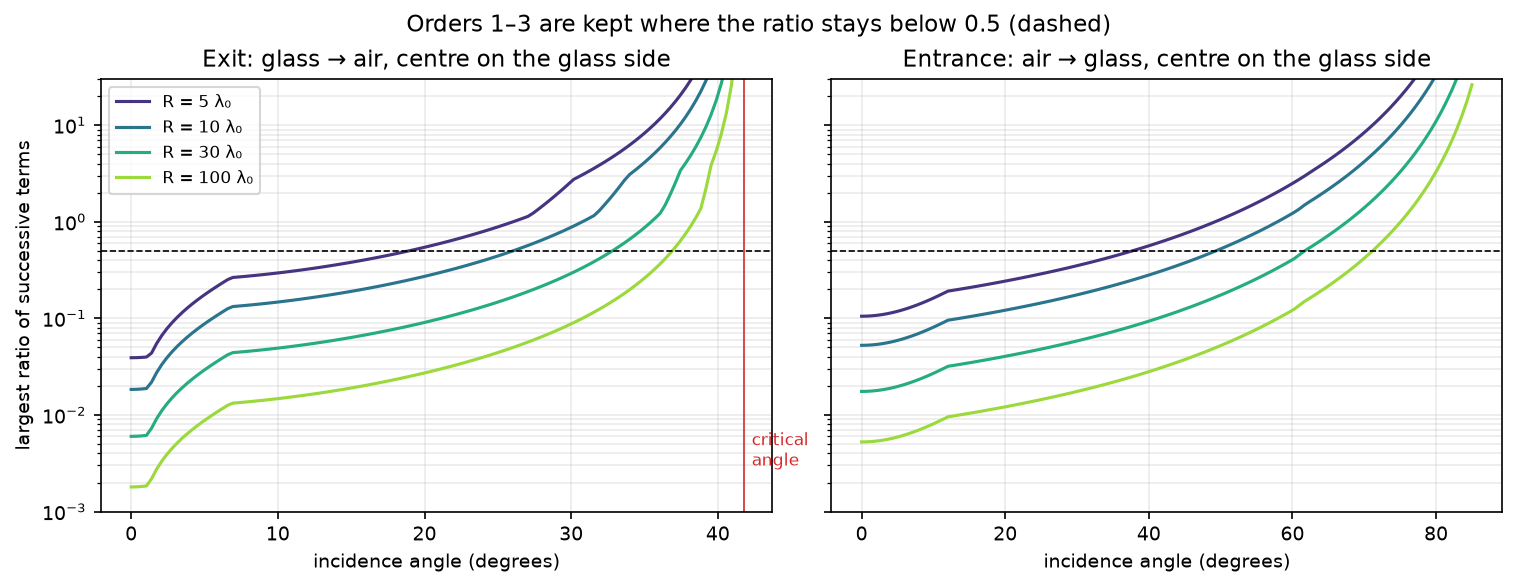

Face,Curvature radius R (λ₀),Largest incidence with order 3 kept (degrees)
Exit,5,18.9
Exit,10,26.0
Exit,30,32.8
Exit,100,36.8
Entrance,5,37.5
Entrance,10,49.2
Entrance,30,61.6
Entrance,100,70.8


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True, layout="constrained")
radii = (5, 10, 30, 100)
shades = plt.cm.viridis(np.linspace(0.15, 0.85, len(radii)))
limit_rows = []
for ax, (title, n1, n2, curvature) in zip(
    axes,
    (
        ("Exit: glass → air, centre on the glass side", 1.5, 1.0, 1),
        ("Entrance: air → glass, centre on the glass side", 1.0, 1.5, -1),
    ),
):
    # Scan to 85 degrees of incidence or of transmission, whichever comes first.
    top = min(np.radians(85), np.arcsin(min(1.0, n2 * np.sin(np.radians(85)) / n1)))
    theta = np.linspace(0, top, 121)
    for radius, color in zip(radii, shades):
        values = canonical_values(radius, 1.0, n1, n2, theta, 3, curvature)[2]
        ratio = series_ratio(np.moveaxis(values, -1, 0), 2 * np.pi * n2 * radius)
        ax.semilogy(np.degrees(theta), ratio, color=color, label=f"R = {radius} λ₀")
        limit = convergent_incidence(radius, 1.0, n1, n2, 3, curvature=curvature)
        limit_rows.append(
            dict(face=title.split(":")[0], R=radius, limit=np.degrees(limit))
        )
    ax.axhline(0.5, color="black", ls="--", lw=0.8)
    if n1 > n2:
        ax.axvline(np.degrees(np.arcsin(n2 / n1)), color="tab:red", lw=0.8)
        ax.text(
            np.degrees(np.arcsin(n2 / n1)) + 0.5,
            3e-3,
            "critical\nangle",
            color="tab:red",
            fontsize=8,
        )
    ax.set(
        xlabel="incidence angle (degrees)",
        title=title,
        ylim=(1e-3, 30),
        ylabel="largest ratio of successive terms" if n1 > n2 else None,
    )
    ax.grid(True, which="both", alpha=0.25)
axes[0].legend(fontsize=8)
fig.suptitle("Orders 1–3 are kept where the ratio stays below 0.5 (dashed)")
plt.show()
table(
    limit_rows,
    [
        ("face", "Face", None),
        ("R", "Curvature radius R (λ₀)", "{:g}"),
        ("limit", "Largest incidence with order 3 kept (degrees)", "{:.1f}"),
    ],
)

The usable range widens with the radius of curvature and is much narrower when
light leaves glass than when it enters: the critical angle, 41.8° for n = 1.5,
caps the exit. Below R ≈ 5λ₀ the exit range is only a few degrees, so a small,
strongly curved lens gains little from the higher orders.

## 3 · When is the single-pass lens model reliable?

Our method follows the wave once through each lens. At the rim it separates the
part of the wave that enters the glass from the part that passes outside, and
propagates them in their own media. Within about √(λ₀T) of the rim, for an
element of centre thickness T, light crosses between those two regions, and
that separation is not exact. The model therefore needs the rim zone to be
small compared with the aperture: a large **element Fresnel number a²/(λ₀T)**.

First, the reference itself. The native BEM, with the same λ₀/3 elements used
below, is compared with the exact Mie field of a 6λ₀ glass sphere on the axis
behind it.

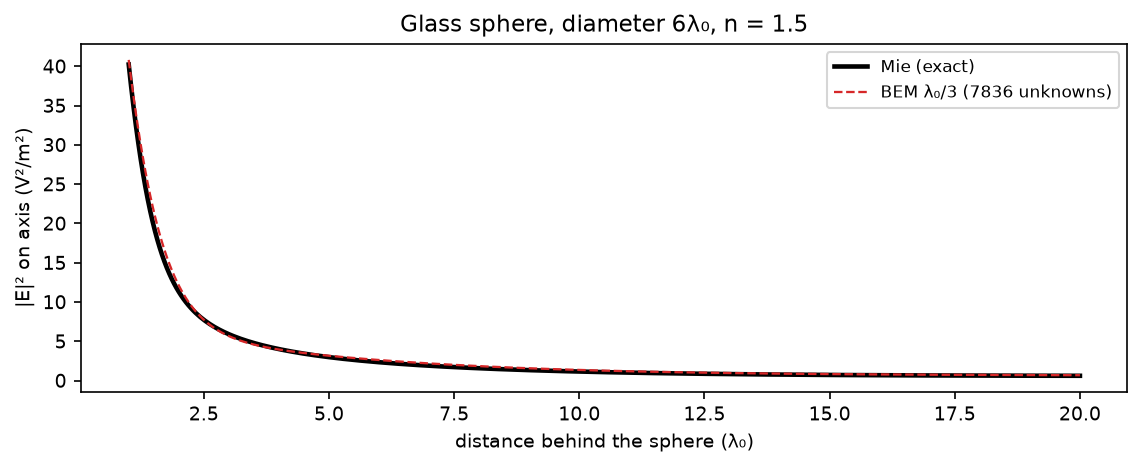

BEM versus Mie, complex field on the axis: **6.9%** relative error.

In [4]:
sphere, sphere_info = study.sphere_control()
z = sphere["z"] / WAVELENGTH - study.DIAMETER / 2
fig, ax = plt.subplots(figsize=(7.5, 3), layout="constrained")
ax.plot(
    z, np.sum(abs(sphere["mie"]) ** 2, -1), color="black", lw=2.2, label="Mie (exact)"
)
ax.plot(
    z,
    np.sum(abs(sphere["bem"]) ** 2, -1),
    color="tab:red",
    lw=1.1,
    ls="--",
    label=f"BEM λ₀/3 ({sphere_info['unknowns']} unknowns)",
)
ax.set(
    xlabel="distance behind the sphere (λ₀)",
    ylabel="|E|² on axis (V²/m²)",
    title="Glass sphere, diameter 6λ₀, n = 1.5",
)
ax.legend(fontsize=8)
plt.show()
error = np.linalg.norm(sphere["bem"] - sphere["mie"]) / np.linalg.norm(sphere["mie"])
display(
    Markdown(
        f"BEM versus Mie, complex field on the axis: **{error:.1%}** relative error."
    )
)

BEM is accurate to a few per cent at this size, so it is a trustworthy
reference for 6λ₀ lenses. Now our model against it, for biconvex lenses with
the same curvature (R = ±20λ₀) and increasing thickness, together with four
thick lenses of stronger curvature and the four thin lenses studied next.

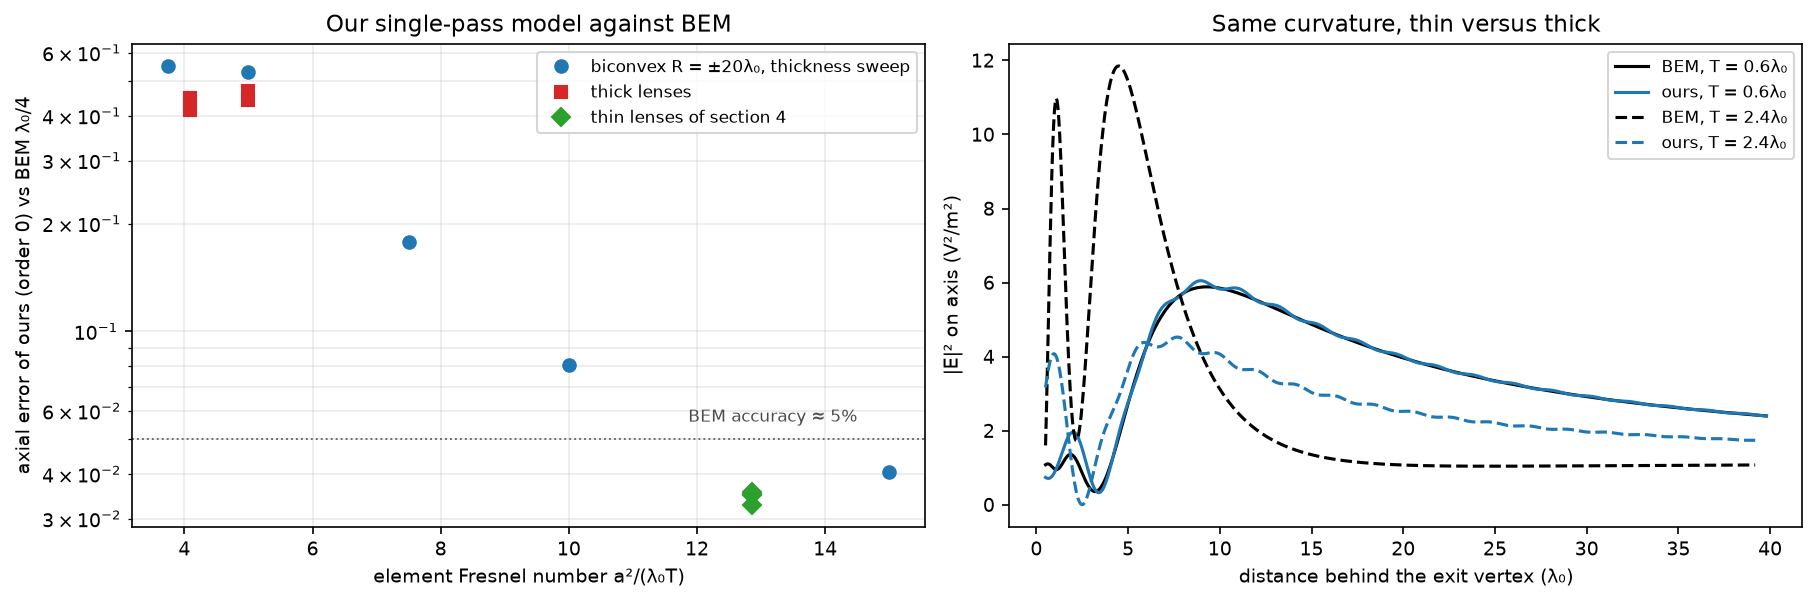

Lens,Centre thickness T (λ₀),Element Fresnel number a²/(λ₀T),Axial error of ours (order 0) vs BEM λ₀/4,"BEM change, λ₀/3 → λ₀/4 elements"
"biconvex R20, T 0.6",0.6,15.0,0.041,0.006
"biconvex R20, T 0.9",0.9,10.0,0.081,0.005
"biconvex R20, T 1.2",1.2,7.5,0.178,0.015
"biconvex R20, T 1.8",1.8,5.0,0.532,0.035
"biconvex R20, T 2.4",2.4,3.8,0.551,0.054
plano-convex,1.8,5.0,0.444,0.054
convex-plano,1.8,5.0,0.468,0.047
biconvex,2.2,4.1,0.415,0.031
asymmetric biconvex,2.2,4.1,0.449,0.018
thin plano-convex,0.7,12.9,0.035,0.010


In [5]:
groups = (
    ("biconvex R = ±20λ₀, thickness sweep", study.SWEEP, "o", "tab:blue"),
    ("thick lenses", study.THICK, "s", "tab:red"),
    ("thin lenses of section 4", study.MAIN, "D", "tab:green"),
)
validity_rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), layout="constrained")
for label, names, marker, color in groups:
    x, y = [], []
    for name in names:
        result, _ = study.case(name, verbose=False)
        m = result["metrics"]
        x.append(study.element_fresnel(name))
        y.append(m["Ours N=0 axial error vs BEM λ/4"])
        validity_rows.append(
            dict(
                name=name,
                T=study.LENSES[name][2],
                fresnel=x[-1],
                error=y[-1],
                bem=m["BEM refinement change"],
            )
        )
    axes[0].plot(x, y, marker, color=color, label=label, ms=6)
axes[0].axhline(0.05, color="0.4", ls=":", lw=0.9)
axes[0].text(14.5, 0.056, "BEM accuracy ≈ 5%", fontsize=8, color="0.3", ha="right")
axes[0].set(
    xlabel="element Fresnel number a²/(λ₀T)",
    ylabel="axial error of ours (order 0) vs BEM λ₀/4",
    yscale="log",
    title="Our single-pass model against BEM",
)
axes[0].grid(True, which="both", alpha=0.25)
axes[0].legend(fontsize=8)
for name, style in ((study.SWEEP[0], "-"), (study.SWEEP[-1], "--")):
    result, data = study.case(name, verbose=False)
    zz = data["z_axis"] / WAVELENGTH - result["exit_vertex_lambda"]
    t = study.LENSES[name][2]
    axes[1].plot(
        zz,
        np.sum(abs(data["BEM λ/4|axis"]) ** 2, -1),
        color="black",
        ls=style,
        label=f"BEM, T = {t:g}λ₀",
    )
    axes[1].plot(
        zz,
        np.sum(abs(data["Ours N=0|axis"]) ** 2, -1),
        color=ORDER_COLORS[0],
        ls=style,
        label=f"ours, T = {t:g}λ₀",
    )
axes[1].set(
    xlabel="distance behind the exit vertex (λ₀)",
    ylabel="|E|² on axis (V²/m²)",
    title="Same curvature, thin versus thick",
)
axes[1].legend(fontsize=8)
plt.show()
table(
    validity_rows,
    [
        ("name", "Lens", None),
        ("T", "Centre thickness T (λ₀)", "{:g}"),
        ("fresnel", "Element Fresnel number a²/(λ₀T)", "{:.1f}"),
        ("error", "Axial error of ours (order 0) vs BEM λ₀/4", "{:.3f}"),
        ("bem", "BEM change, λ₀/3 → λ₀/4 elements", "{:.3f}"),
    ],
)

The error of our model is set by the element Fresnel number, not by curvature
order. Thick lenses of this size (a²/(λ₀T) ≈ 4–5) are 40–50% off, even though
our chain conserves power: BEM shows light concentrating behind a thick glass
cylinder far more than a single pass predicts. Below, the lenses are thin enough
(a²/(λ₀T) ≈ 13) for the model to be meaningful, so the order comparison is
not swamped by this unrelated error.

## 4 · Four thin curved lenses

All four lenses have diameter D = 6λ₀ (clear radius a = 3λ₀), centre
thickness 0.7λ₀, n = 1.5 and a cylindrical rim. This is the largest size for
which the native BEM can be checked at two element sizes (λ₀/3 and λ₀/4). The
imaging Fresnel number a²/(λ₀f) is below 1, so every focus here is strongly
shaped by diffraction.

Our method runs the same forward chain twice, with the interaction at order 0
and at order 3, on a 256² FFT lattice 24a wide. Nothing else changes between
the two runs. BEM solves the complete lens, including rim scattering and
internal reflections that our single forward pass omits.

In [6]:
lens_results = {}
for name in study.MAIN:
    t0 = perf_counter()
    lens_results[name] = study.case(name)
    print(f"{name}: {perf_counter() - t0:.1f} s (cached results are reused)")

thin plano-convex: 0.0 s (cached results are reused)
thin convex-plano: 0.0 s (cached results are reused)
thin biconvex: 0.0 s (cached results are reused)
thin asymmetric biconvex: 0.0 s (cached results are reused)


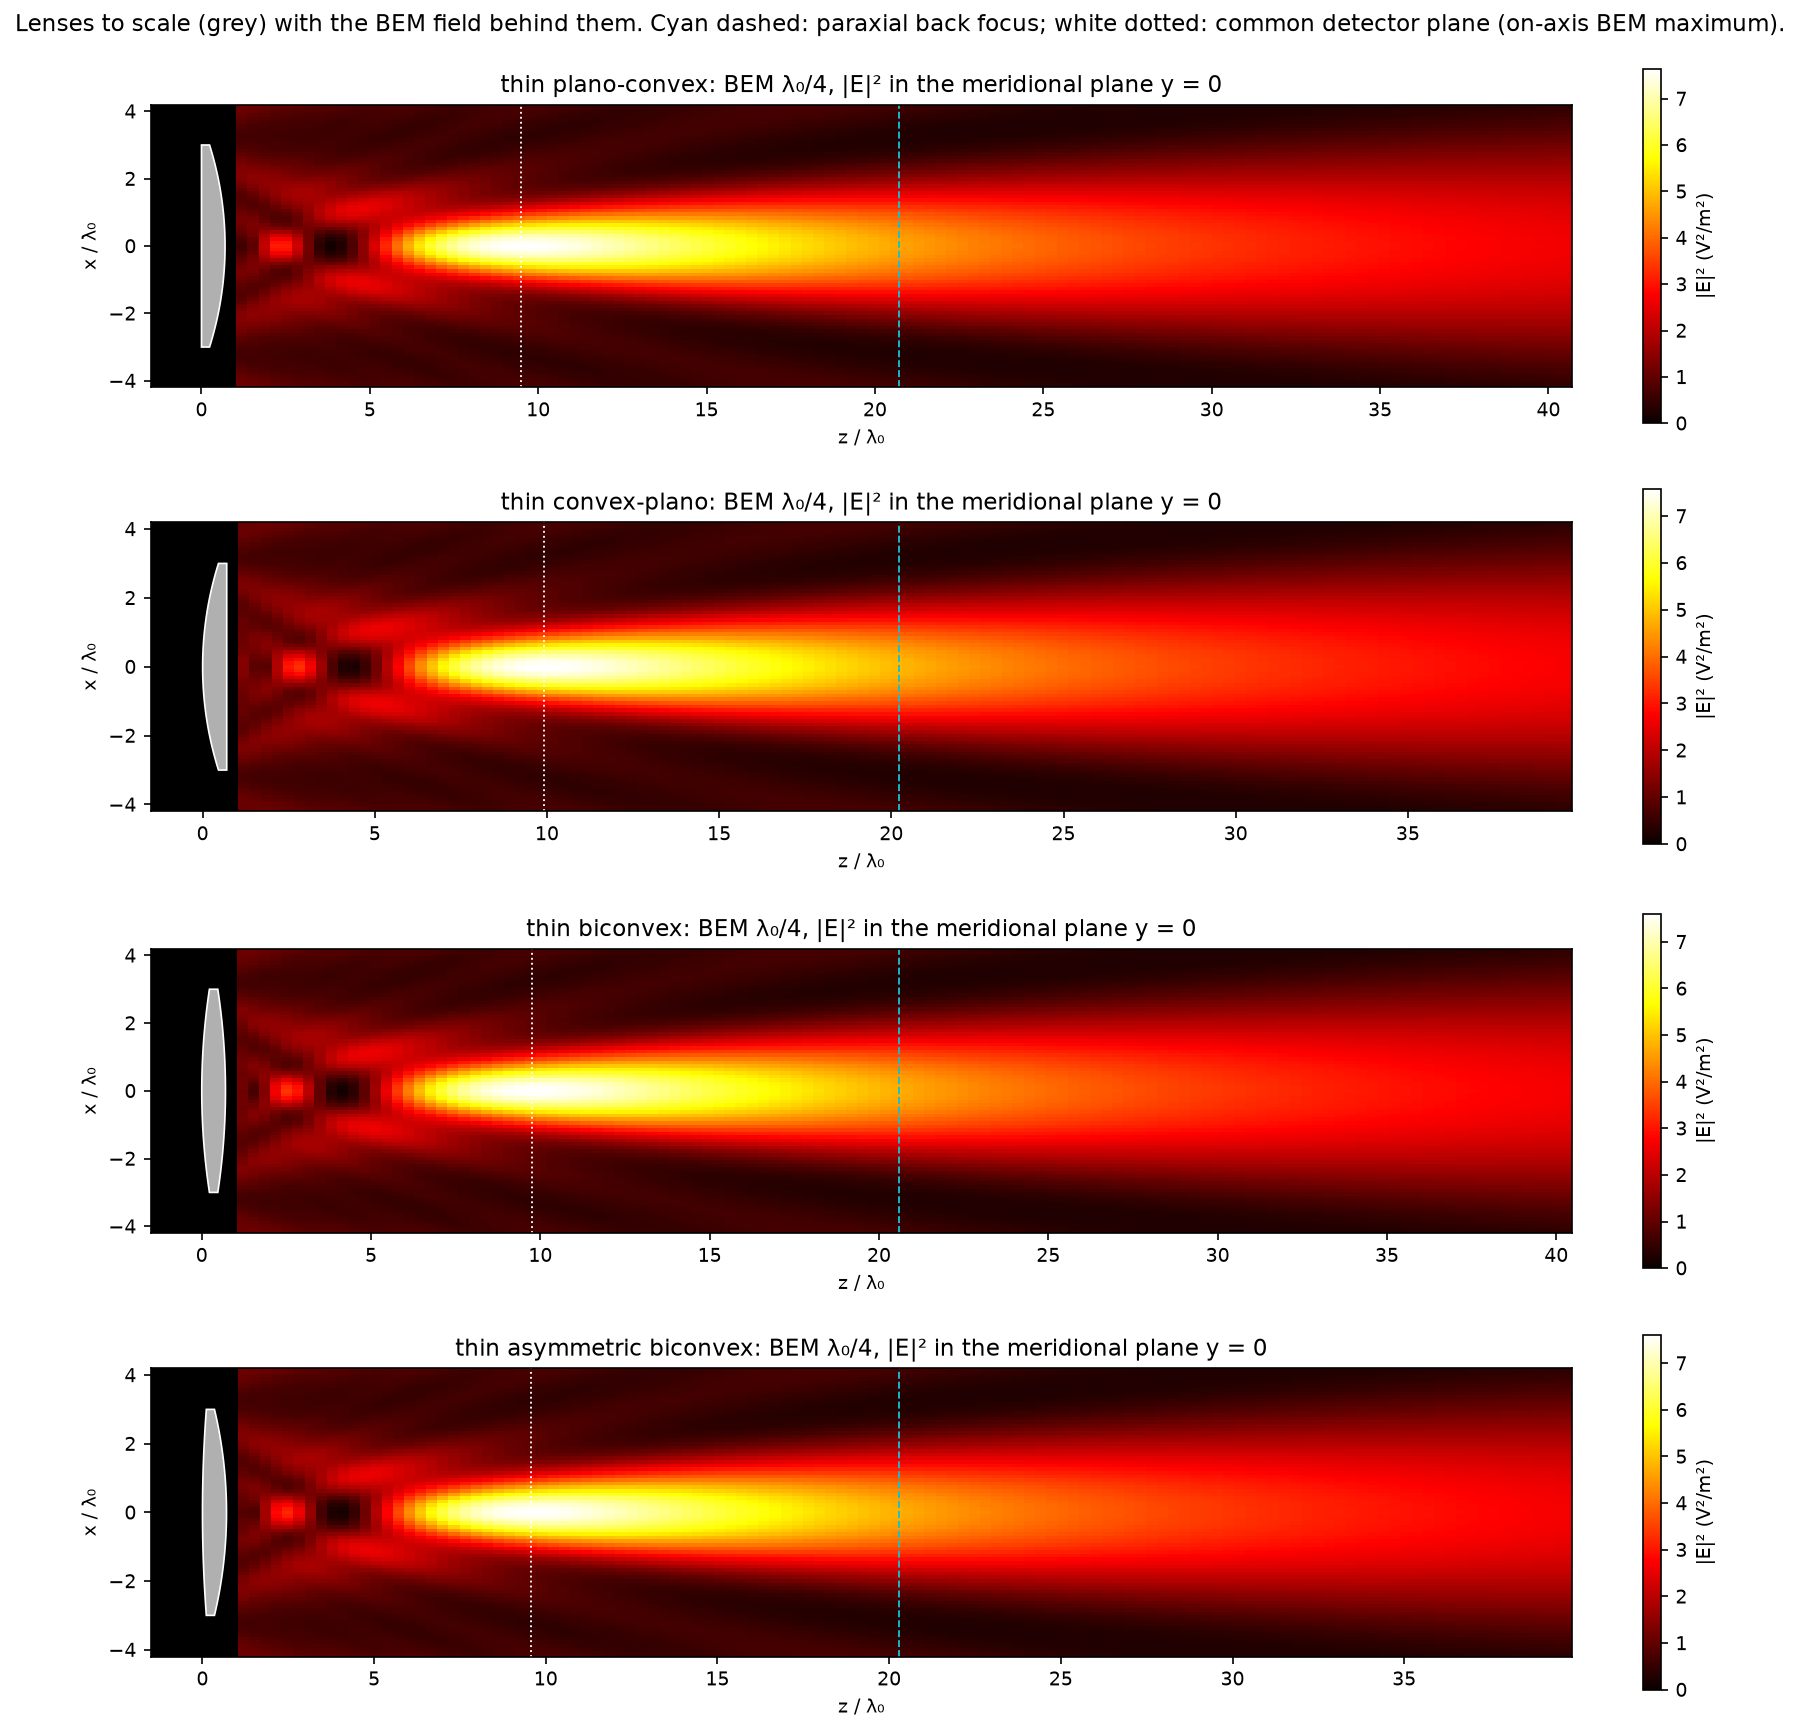

Lens,Entrance radius (λ₀; + centre in the glass),Exit radius (λ₀; − centre in the glass),Centre thickness (λ₀),Paraxial back focal distance (λ₀),Imaging Fresnel number a²/(λ₀ f),Element Fresnel number a²/(λ₀T)
thin plano-convex,plane,-10,0.7,20.0,0.45,12.9
thin convex-plano,10,plane,0.7,19.5,0.46,12.9
thin biconvex,20,-20,0.7,19.9,0.45,12.9
thin asymmetric biconvex,40,-13,0.7,19.6,0.46,12.9


In [7]:
geometry_rows = []
fig, axes = plt.subplots(4, 1, figsize=(11, 11.5), layout="constrained")
for ax, name in zip(axes, study.MAIN):
    result, data = lens_results[name]
    front, back = study.surfaces(name)
    a = study.DIAMETER / 2 * WAVELENGTH
    # BEM |E|^2 behind the lens, then the lens itself on top, all to scale.
    field = np.sum(abs(data["BEM λ/4|map"]) ** 2, -1)
    ax.set_facecolor("black")
    im = ax.pcolormesh(
        data["z_map"] / WAVELENGTH,
        data["x_map"] / WAVELENGTH,
        field,
        cmap="hot",
        shading="nearest",
        norm=Normalize(0, float(field.max())),
    )
    x = np.linspace(-a, a, 201)
    xy = np.column_stack((x, 0 * x))
    zf = front.height(xy) + front.frame.origin[2]
    zb = back.height(xy) + back.frame.origin[2]
    ax.fill(
        np.r_[zf, zb[::-1]] / WAVELENGTH,
        np.r_[x, x[::-1]] / WAVELENGTH,
        color="#b0b0b0",
        ec="white",
        lw=0.8,
        zorder=5,
    )
    focus = back.frame.origin[2] + study.paraxial_focus(name)
    ax.axvline(focus / WAVELENGTH, color="tab:cyan", ls="--", lw=0.9)
    ax.axvline(result["detector_z_lambda"], color="white", ls=":", lw=0.9)
    ax.set(
        title=f"{name}: BEM λ₀/4, |E|² in the meridional plane y = 0",
        xlabel="z / λ₀",
        ylabel="x / λ₀",
        xlim=(-1.5, data["z_map"][-1] / WAVELENGTH),
        ylim=(data["x_map"][0] / WAVELENGTH, data["x_map"][-1] / WAVELENGTH),
    )
    ax.set_aspect("equal")
    fig.colorbar(im, ax=ax, label="|E|² (V²/m²)", shrink=0.9)
    front_r, back_r, thickness = study.LENSES[name]
    f = study.paraxial_focus(name) / WAVELENGTH
    geometry_rows.append(
        dict(
            name=name,
            front="plane" if front_r is None else f"{front_r:g}",
            back="plane" if back_r is None else f"{back_r:g}",
            thickness=thickness,
            f=f,
            fresnel=(study.DIAMETER / 2) ** 2 / f,
            element=study.element_fresnel(name),
        )
    )
fig.suptitle(
    "Lenses to scale (grey) with the BEM field behind them. Cyan dashed: paraxial "
    "back focus; white dotted: common detector plane (on-axis BEM maximum)."
)
plt.show()
table(
    geometry_rows,
    [
        ("name", "Lens", None),
        ("front", "Entrance radius (λ₀; + centre in the glass)", None),
        ("back", "Exit radius (λ₀; − centre in the glass)", None),
        ("thickness", "Centre thickness (λ₀)", "{:g}"),
        ("f", "Paraxial back focal distance (λ₀)", "{:.1f}"),
        ("fresnel", "Imaging Fresnel number a²/(λ₀ f)", "{:.2f}"),
        ("element", "Element Fresnel number a²/(λ₀T)", "{:.1f}"),
    ],
)

## 5 · Fields behind the lenses

Each figure shows the meridional plane y = 0 behind the exit face:

- **top:** |E|² from BEM (λ₀/4 elements) and from our order-3 run;
- **bottom left:** |E(order 3) − E(order 0)|, the field that the curvature
  corrections add, on its own scale;
- **bottom right:** |E(order 3) − E(BEM)|, the remaining disagreement with the
  full-wave solution.

The cyan dashed line is the common detector plane: the on-axis maximum of BEM
more than 1λ₀ behind the lens. Every method is evaluated at that same plane.

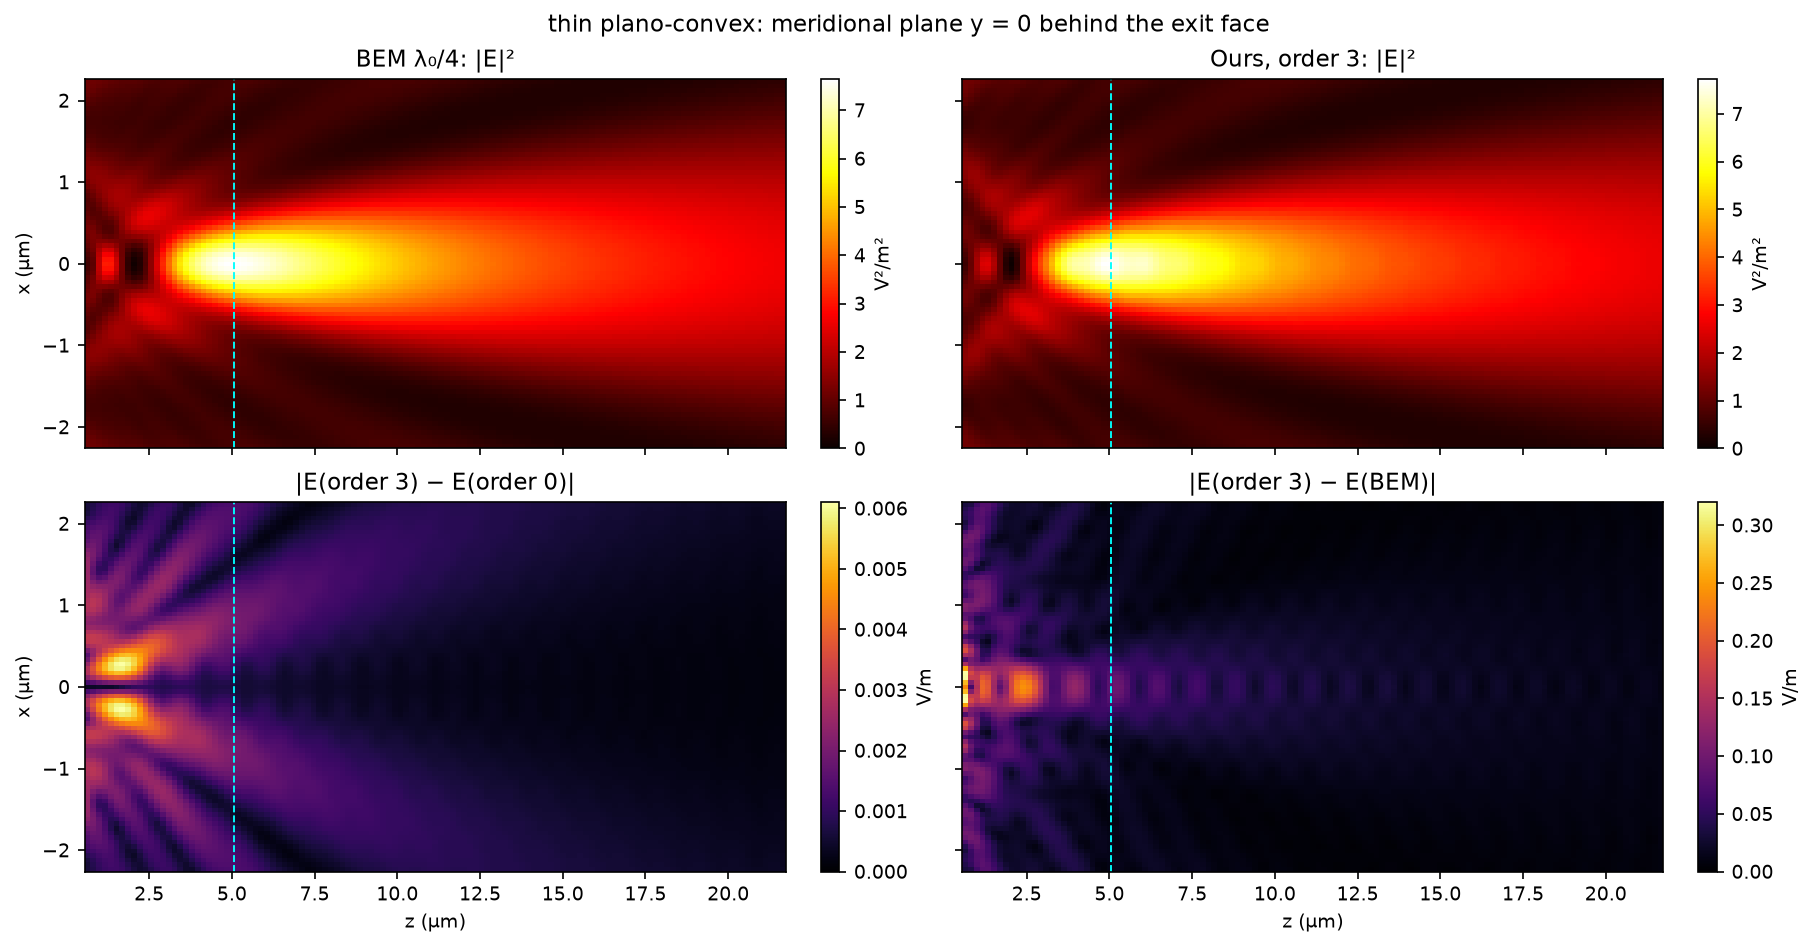

In [8]:
UM = 1e-6


def meridian(name):
    result, data = lens_results[name]
    z, x = data["z_map"], data["x_map"]
    bem, e0, e3 = (data[f"{k}|map"] for k in ("BEM λ/4", "Ours N=0", "Ours N=3"))
    panels = (
        (np.sum(abs(bem) ** 2, -1), "BEM λ₀/4: |E|²", "V²/m²", "hot"),
        (np.sum(abs(e3) ** 2, -1), "Ours, order 3: |E|²", "V²/m²", "hot"),
        (
            np.linalg.norm(e3 - e0, axis=-1),
            "|E(order 3) − E(order 0)|",
            "V/m",
            "inferno",
        ),
        (np.linalg.norm(e3 - bem, axis=-1), "|E(order 3) − E(BEM)|", "V/m", "inferno"),
    )
    fig, axes = plt.subplots(
        2, 2, figsize=(12, 6.2), sharex=True, sharey=True, layout="constrained"
    )
    detector = result["detector_z_lambda"] * WAVELENGTH
    for ax, (values, title, unit, cmap) in zip(axes.flat, panels):
        im = ax.pcolormesh(
            z / UM,
            x / UM,
            values,
            cmap=cmap,
            shading="nearest",
            norm=Normalize(0, float(values.max())),
        )
        ax.axvline(detector / UM, color="cyan", ls="--", lw=0.9)
        ax.set(
            title=title,
            xlabel="z (µm)" if ax in axes[1] else None,
            ylabel="x (µm)" if ax in axes[:, 0] else None,
        )
        fig.colorbar(im, ax=ax, label=unit)
    fig.suptitle(f"{name}: meridional plane y = 0 behind the exit face")
    plt.show()


meridian("thin plano-convex")

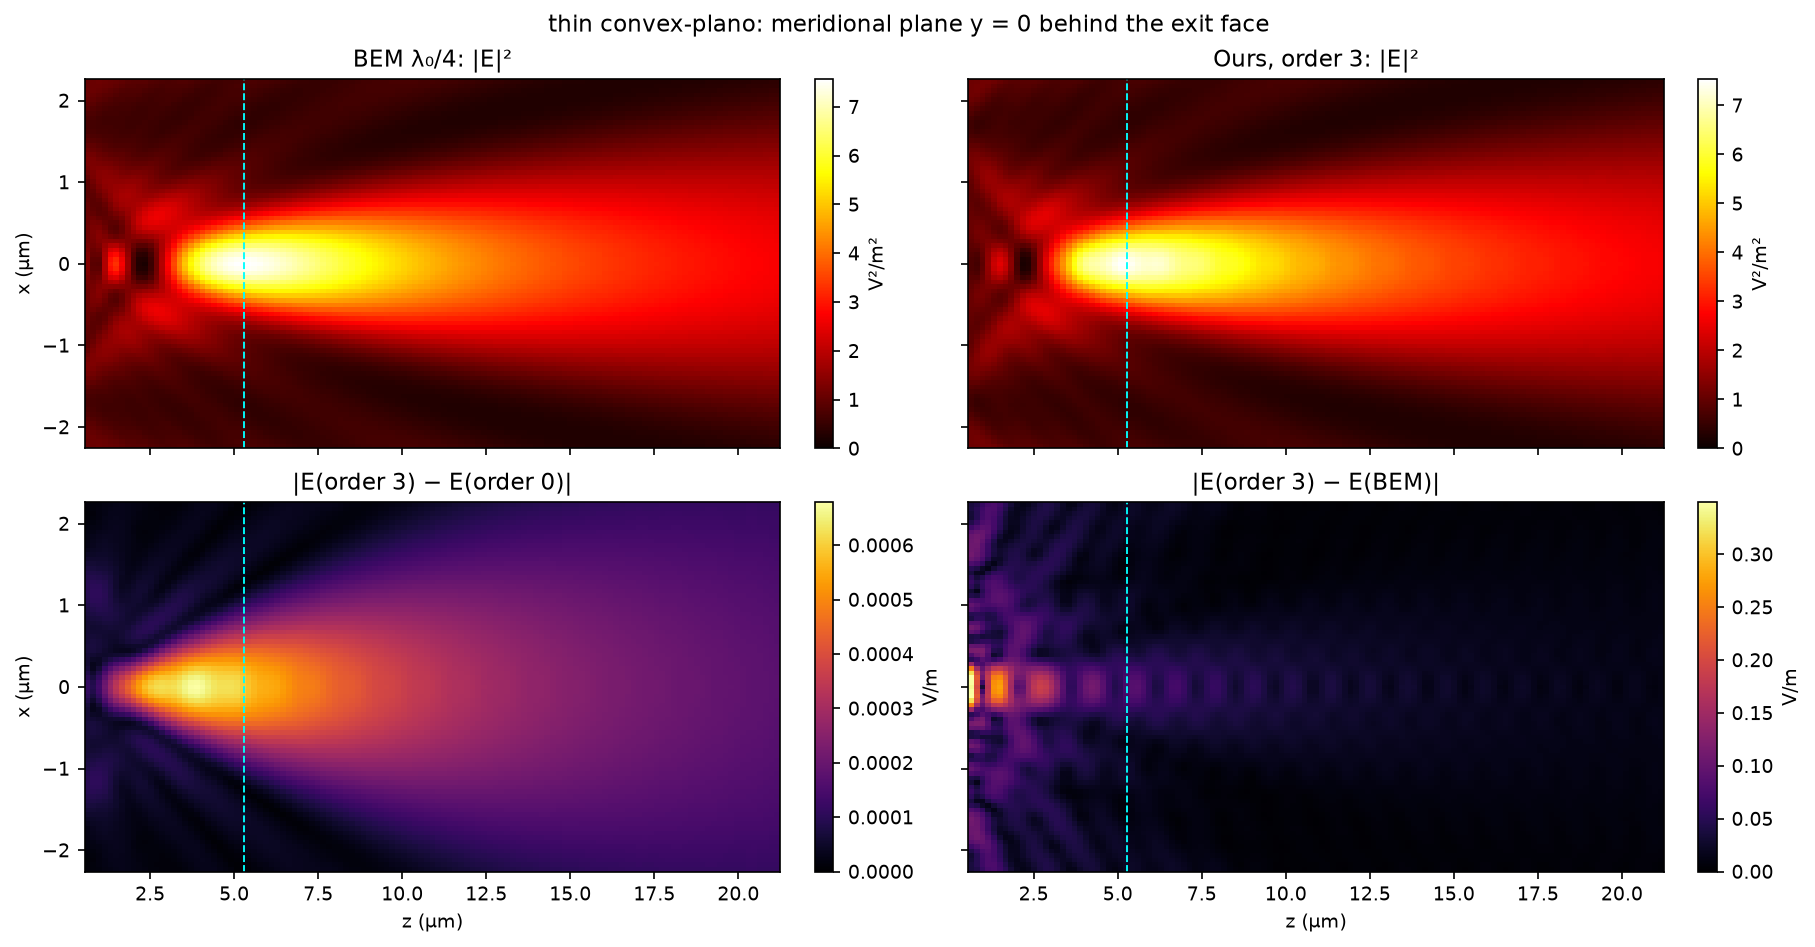

In [9]:
meridian("thin convex-plano")

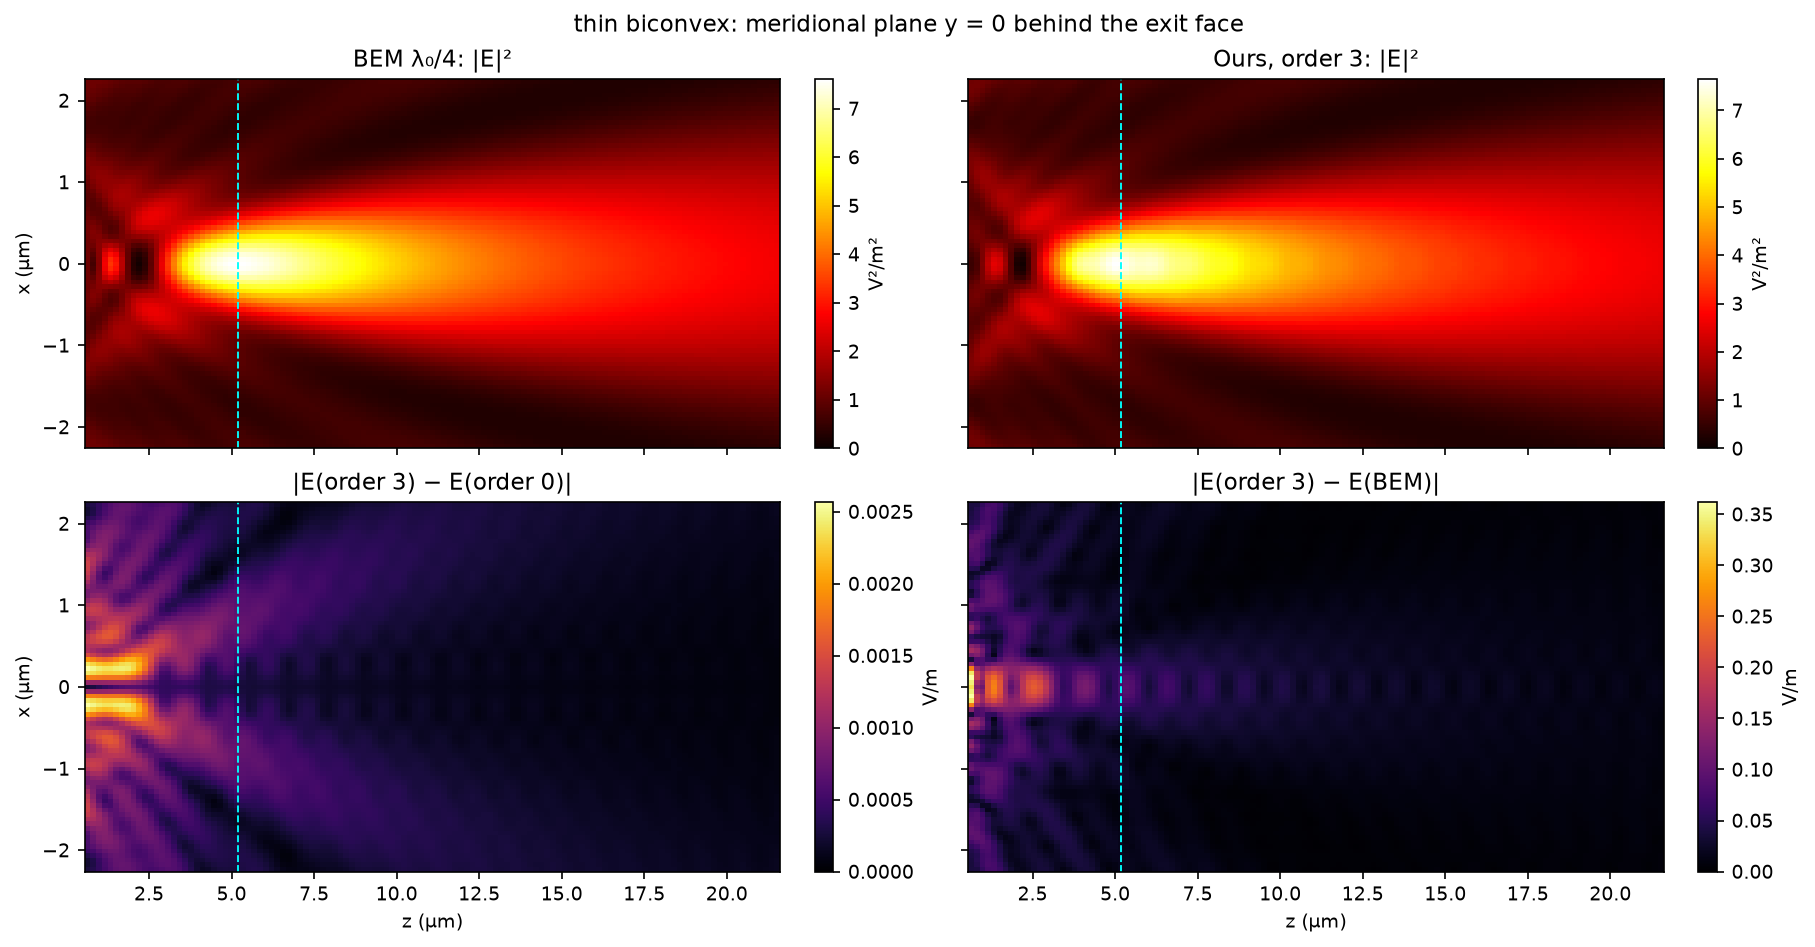

In [10]:
meridian("thin biconvex")

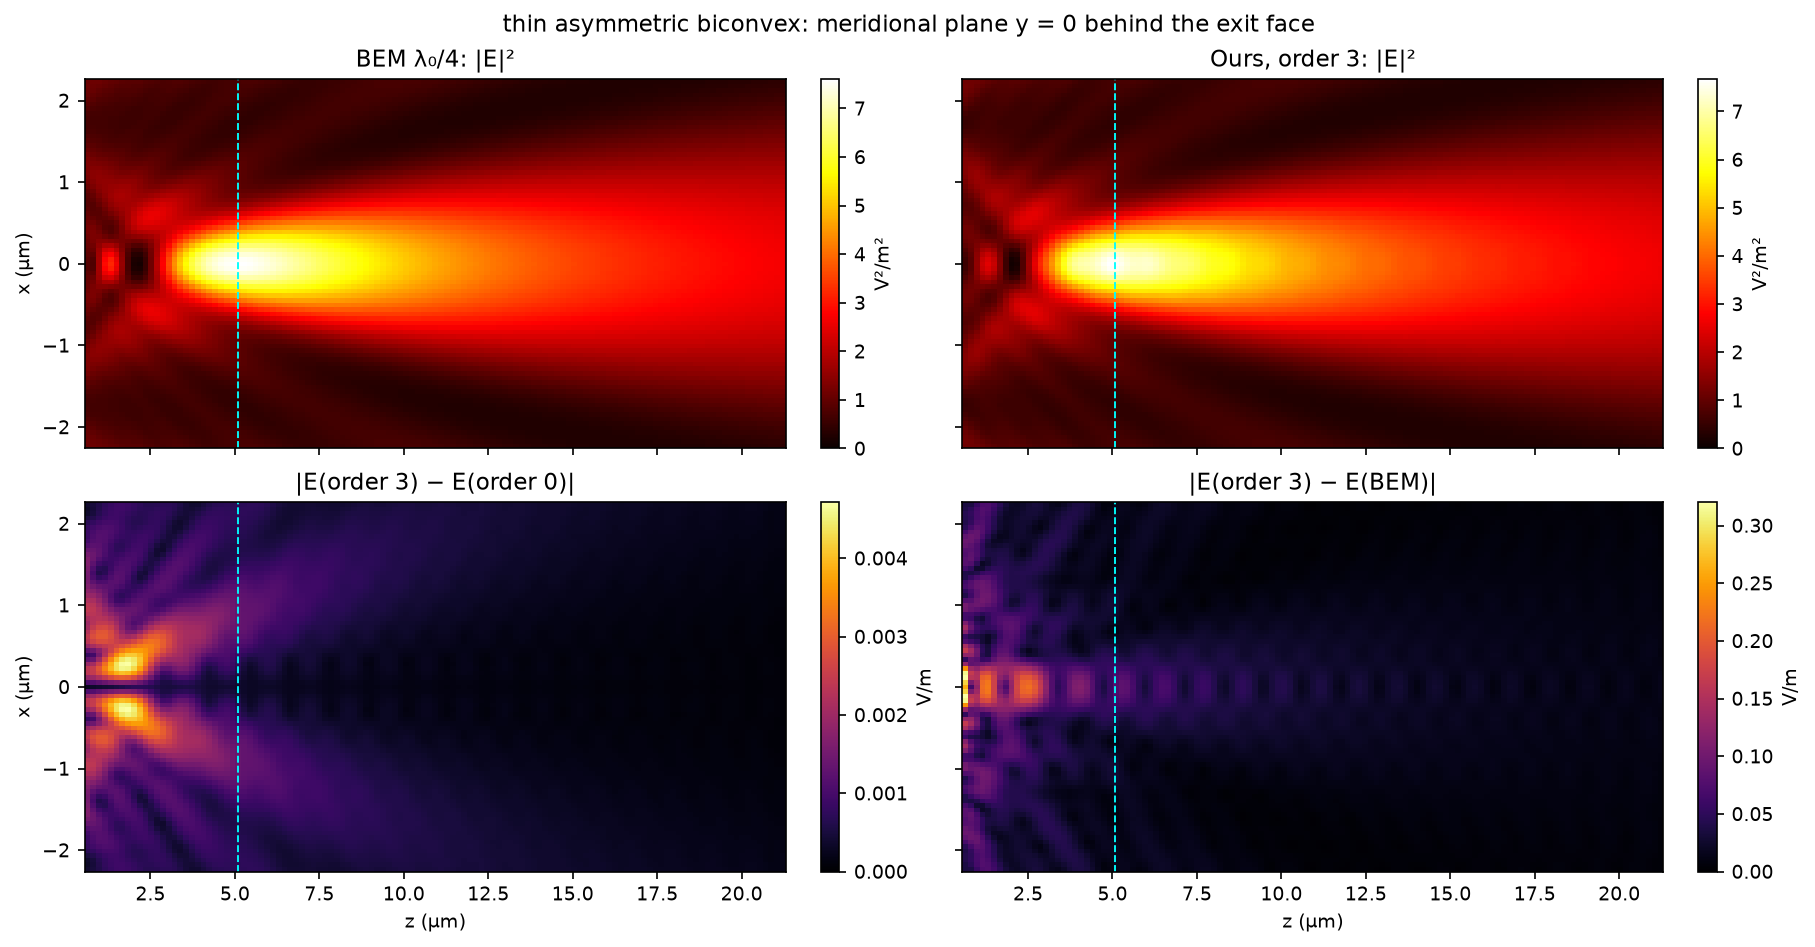

In [11]:
meridian("thin asymmetric biconvex")

## 6 · On the axis and in the focal plane

Axial profiles show |E|² from BEM at both element sizes, our order-0 and
order-3 runs, and Stratton–Chu radiation of our own order-3 exit field. The
second row compares two differences on a logarithmic scale: what order 3
changes in our field, and how much BEM itself changes between λ₀/3 and λ₀/4
elements. A curvature effect smaller than the BEM refinement change cannot be
confirmed or refuted by this reference.

The detector plane is the axial intensity maximum of BEM, only about 9λ₀
behind these lenses: at a Fresnel number a²/(λ₀d) near 1 the focus moves far
short of the paraxial one and is a single broad peak. The focal-plane window
reaches max(2.3λ₀/NA, 2a + 6λ₀) so that at least three secondary maxima are
shown on each side (the figure counts them). Beyond |x| ≈ a they are the edge
fringes of the light passing outside the lens, which is kept (no stop).
Intensities are drawn on linear scales.

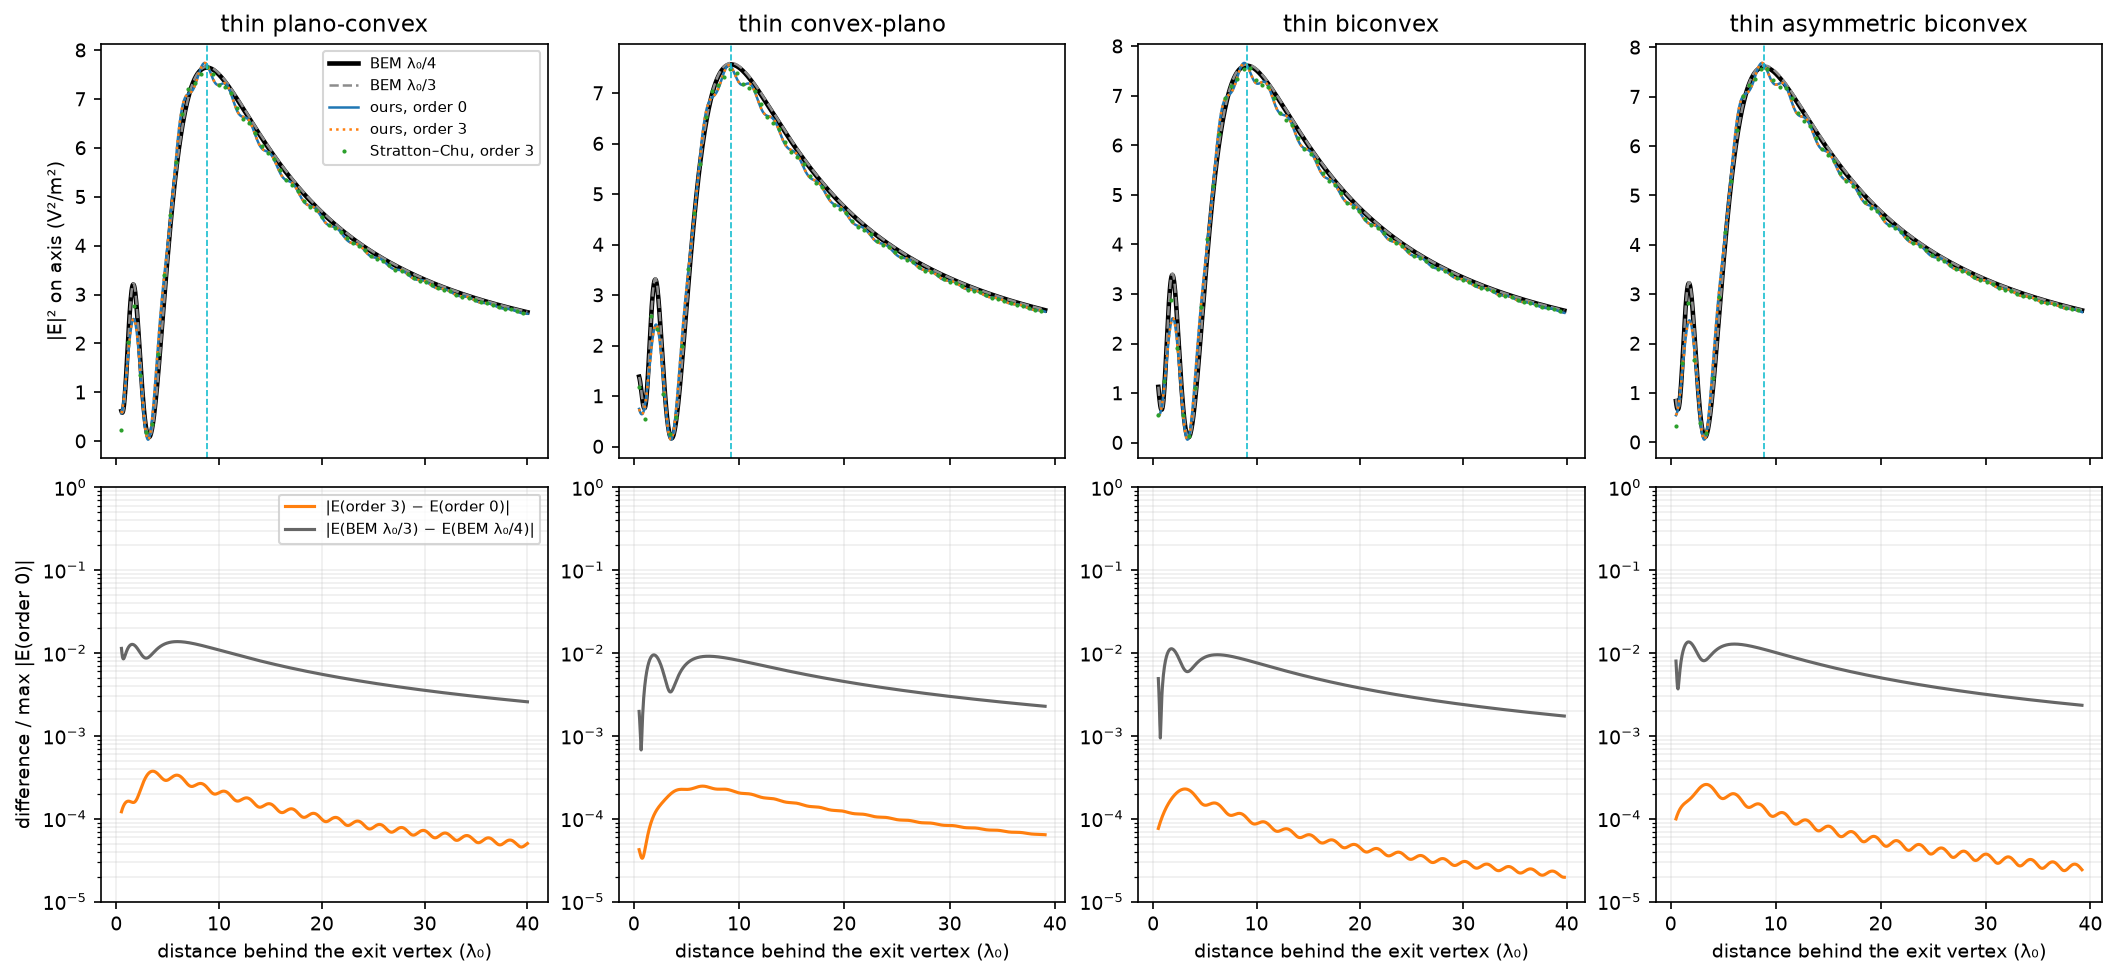

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6.4), layout="constrained", sharex="col")
for column, name in enumerate(study.MAIN):
    result, data = lens_results[name]
    exit_z = result["exit_vertex_lambda"]
    z = data["z_axis"] / WAVELENGTH - exit_z
    ax = axes[0, column]
    styles = (
        ("BEM λ/4", "BEM λ₀/4", dict(color="black", lw=2.2)),
        ("BEM λ/3", "BEM λ₀/3", dict(color="0.55", lw=1.2, ls="--")),
        ("Ours N=0", "ours, order 0", dict(color=ORDER_COLORS[0], lw=1.2)),
        ("Ours N=3", "ours, order 3", dict(color=ORDER_COLORS[3], lw=1.2, ls=":")),
        (
            "Stratton–Chu N=3",
            "Stratton–Chu, order 3",
            dict(color="tab:green", lw=0, marker=".", ms=2, markevery=12),
        ),
    )
    for key, label, style in styles:
        ax.plot(z, np.sum(abs(data[f"{key}|axis"]) ** 2, -1), label=label, **style)
    ax.axvline(result["detector_z_lambda"] - exit_z, color="tab:cyan", ls="--", lw=0.8)
    ax.set(title=name, ylabel="|E|² on axis (V²/m²)" if column == 0 else None)
    peak = np.max(np.abs(data["Ours N=0|axis"]))
    ax = axes[1, column]
    ax.semilogy(
        z,
        np.linalg.norm(data["Ours N=3|axis"] - data["Ours N=0|axis"], axis=-1) / peak,
        color=ORDER_COLORS[3],
        label="|E(order 3) − E(order 0)|",
    )
    ax.semilogy(
        z,
        np.linalg.norm(data["BEM λ/3|axis"] - data["BEM λ/4|axis"], axis=-1) / peak,
        color="0.4",
        label="|E(BEM λ₀/3) − E(BEM λ₀/4)|",
    )
    ax.set(
        xlabel="distance behind the exit vertex (λ₀)",
        ylim=(1e-5, 1),
        ylabel="difference / max |E(order 0)|" if column == 0 else None,
    )
    ax.grid(True, which="both", alpha=0.2)
axes[0, 0].legend(fontsize=7)
axes[1, 0].legend(fontsize=7)
plt.show()

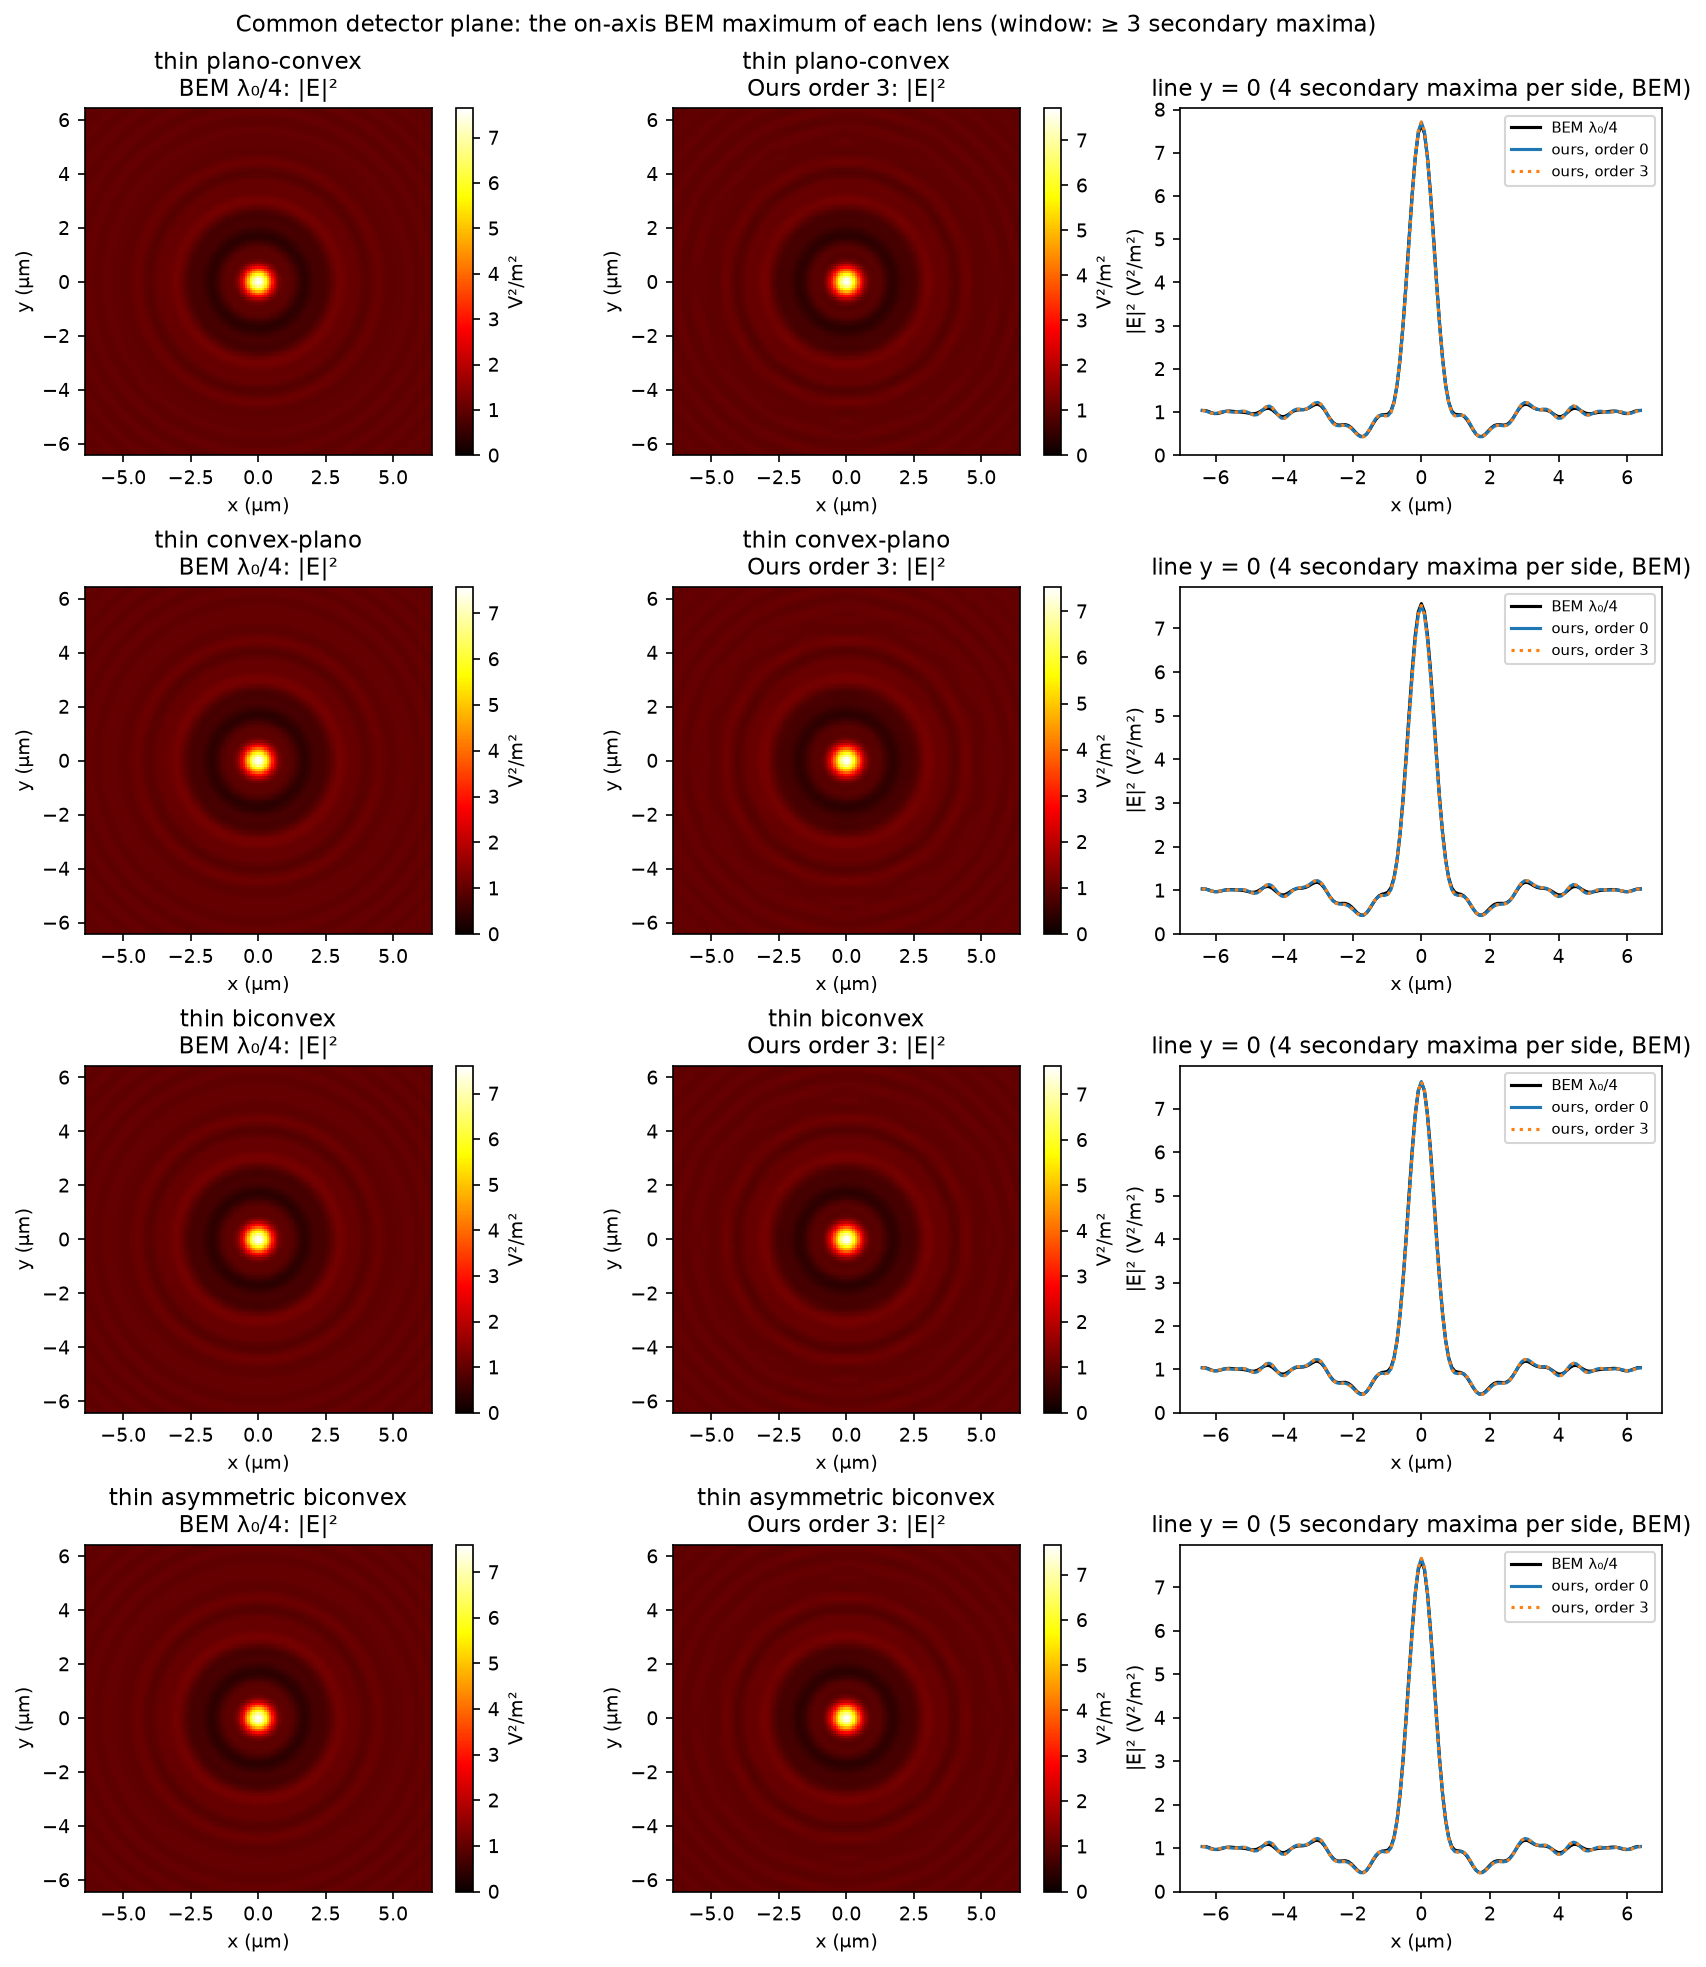

In [13]:
fig, axes = plt.subplots(4, 3, figsize=(11.5, 13), layout="constrained")
lobe_counts = {}
for row, name in enumerate(study.MAIN):
    result, data = lens_results[name]
    axis = data["focal_axis"]
    for column, key in enumerate(("BEM λ/4", "Ours N=3")):
        values = np.sum(abs(data[f"{key}|focal"]) ** 2, -1)
        ax = axes[row, column]
        im = ax.pcolormesh(
            axis / UM,
            axis / UM,
            values,
            cmap="hot",
            shading="nearest",
            vmin=0,
            vmax=float(values.max()),
        )
        ax.set(
            aspect="equal",
            title=f"{name}\n{key.replace('N=3', 'order 3').replace('λ/4', 'λ₀/4')}: |E|²",
            xlabel="x (µm)",
            ylabel="y (µm)",
        )
        fig.colorbar(im, ax=ax, label="V²/m²")
    ax = axes[row, 2]
    middle = len(axis) // 2
    for key, label, color, style in (
        ("BEM λ/4", "BEM λ₀/4", "black", "-"),
        ("Ours N=0", "ours, order 0", ORDER_COLORS[0], "-"),
        ("Ours N=3", "ours, order 3", ORDER_COLORS[3], ":"),
    ):
        ax.plot(
            axis / UM,
            np.sum(abs(data[f"{key}|focal"][middle]) ** 2, -1),
            color=color,
            ls=style,
            label=label,
        )
    line = np.sum(abs(data["BEM λ/4|focal"][middle]) ** 2, -1)
    right = line[middle:]
    lobes = int(np.sum((right[1:-1] > right[:-2]) & (right[1:-1] > right[2:])))
    lobe_counts[name] = lobes
    ax.set(
        title=f"line y = 0 ({lobes} secondary maxima per side, BEM)",
        xlabel="x (µm)",
        ylabel="|E|² (V²/m²)",
        ylim=(0, 1.05 * float(line.max())),
    )
    ax.legend(fontsize=7)
fig.suptitle(
    "Common detector plane: the on-axis BEM maximum of each lens (window: ≥ 3 secondary maxima)"
)
plt.show()
assert min(lobe_counts.values()) >= 3, lobe_counts

## 7 · The numbers

Axial quantities use the complex field on the axis from 1λ₀ behind the exit
vertex to the end of the window. Focal-disk power is the integrated axial
Poynting flux through a disk of radius 1.5λ₀ in the detector plane.

In [14]:
rows_accuracy, rows_power, rows_boundary = [], [], []
for name in study.MAIN:
    result, _ = lens_results[name]
    m = result["metrics"]
    reference = "BEM λ/4"
    rows_accuracy.append(
        dict(
            name=name,
            e0=m[f"Ours N=0 axial error vs {reference}"],
            e3=m[f"Ours N=3 axial error vs {reference}"],
            bem=m["BEM refinement change"],
            change=m["axial change N=0 to N=3"],
            sc=m["Stratton–Chu vs Q^-1 N=3"],
        )
    )
    fw = 1e-15
    rows_power.append(
        dict(
            name=name,
            pb=m[f"{reference} peak |E|^2"],
            p0=m["Ours N=0 peak |E|^2"],
            p3=m["Ours N=3 peak |E|^2"],
            fb=m[f"{reference} focal disk power"] / fw,
            f0=m["Ours N=0 focal disk power"] / fw,
            f3=m["Ours N=3 focal disk power"] / fw,
        )
    )
    rows_boundary.append(
        dict(
            name=name,
            h0=m["Ours N=0 exit jumps"]["tangential_H"],
            h3=m["Ours N=3 exit jumps"]["tangential_H"],
            s0=m["Ours N=0 exit jumps"]["normal_flux_L2"],
            s3=m["Ours N=3 exit jumps"]["normal_flux_L2"],
            share=m.get("share of exit spectral power with order 3 active"),
        )
    )
display(Markdown("**Accuracy on the axis (relative L2 norm of the complex field)**"))
table(
    rows_accuracy,
    [
        ("name", "Lens", None),
        ("e0", "Error of ours, order 0, vs BEM λ₀/4", "{:.3f}"),
        ("e3", "Error of ours, order 3, vs BEM λ₀/4", "{:.3f}"),
        ("bem", "BEM change, λ₀/3 → λ₀/4 elements", "{:.3f}"),
        ("change", "Change of ours, order 0 → order 3", "{:.1e}"),
        ("sc", "Stratton–Chu vs our propagation, order 3", "{:.1e}"),
    ],
)
display(
    Markdown(
        "**Focusing: peak intensity on the axis and power through the focal disk**"
    )
)
table(
    rows_power,
    [
        ("name", "Lens", None),
        ("pb", "Peak |E|², BEM λ₀/4 (V²/m²)", "{:.3f}"),
        ("p0", "Peak |E|², ours order 0 (V²/m²)", "{:.3f}"),
        ("p3", "Peak |E|², ours order 3 (V²/m²)", "{:.3f}"),
        ("fb", "Focal-disk power, BEM λ₀/4 (fW)", "{:.3f}"),
        ("f0", "Focal-disk power, ours order 0 (fW)", "{:.3f}"),
        ("f3", "Focal-disk power, ours order 3 (fW)", "{:.3f}"),
    ],
)
display(
    Markdown(
        "**Boundary conditions on the exit face, inside the edge (relative jumps)**"
    )
)
table(
    rows_boundary,
    [
        ("name", "Lens", None),
        ("h0", "Tangential Z₀H jump, order 0", "{:.2e}"),
        ("h3", "Tangential Z₀H jump, order 3", "{:.2e}"),
        ("s0", "Normal-flux jump, order 0", "{:.2e}"),
        ("s3", "Normal-flux jump, order 3", "{:.2e}"),
        ("share", "Share of exit spectral power with order 3 applied", "{:.2f}"),
    ],
)

**Accuracy on the axis (relative L2 norm of the complex field)**

Lens,"Error of ours, order 0, vs BEM λ₀/4","Error of ours, order 3, vs BEM λ₀/4","BEM change, λ₀/3 → λ₀/4 elements","Change of ours, order 0 → order 3","Stratton–Chu vs our propagation, order 3"
thin plano-convex,0.035,0.035,0.010,2.2e-04,1.8e-02
thin convex-plano,0.035,0.035,0.007,1.9e-04,2.5e-02
thin biconvex,0.036,0.036,0.007,1.1e-04,2.1e-02
thin asymmetric biconvex,0.033,0.033,0.009,1.3e-04,1.9e-02


**Focusing: peak intensity on the axis and power through the focal disk**

Lens,"Peak |E|², BEM λ₀/4 (V²/m²)","Peak |E|², ours order 0 (V²/m²)","Peak |E|², ours order 3 (V²/m²)","Focal-disk power, BEM λ₀/4 (fW)","Focal-disk power, ours order 0 (fW)","Focal-disk power, ours order 3 (fW)"
thin plano-convex,7.644,7.738,7.740,8.454,8.417,8.418
thin convex-plano,7.569,7.550,7.551,8.577,8.473,8.474
thin biconvex,7.607,7.662,7.663,8.521,8.464,8.464
thin asymmetric biconvex,7.602,7.684,7.685,8.453,8.410,8.410


**Boundary conditions on the exit face, inside the edge (relative jumps)**

Lens,"Tangential Z₀H jump, order 0","Tangential Z₀H jump, order 3","Normal-flux jump, order 0","Normal-flux jump, order 3",Share of exit spectral power with order 3 applied
thin plano-convex,2.56e-03,2.26e-03,7.11e-04,1.09e-03,0.95
thin convex-plano,3.61e-14,3.59e-14,2.78e-14,2.77e-14,—
thin biconvex,1.18e-03,7.05e-04,5.04e-04,2.71e-04,0.97
thin asymmetric biconvex,1.79e-03,1.46e-03,7.63e-04,6.02e-04,0.96


## 8 · Where order 3 matters

The lens results above are a genuine finding: in one pass through a thin lens,
the curvature corrections change the propagated field by about 10⁻⁴. The
corrections are largest near the rim and at steep incidence, where little of the
light travels. Order 3 matters wherever the order-0 error itself matters. There
are three such situations, shown below with exact references where they exist:

1. **Fields at the surface of a strongly curved interface**, at oblique
   incidence, compared with the exact single-interface field.
2. **Glass → air exits approaching the critical angle**, where the first
   correction grows to 2–3% of the field.
3. **Repeated encounters**, in section 9, where small local errors accumulate.

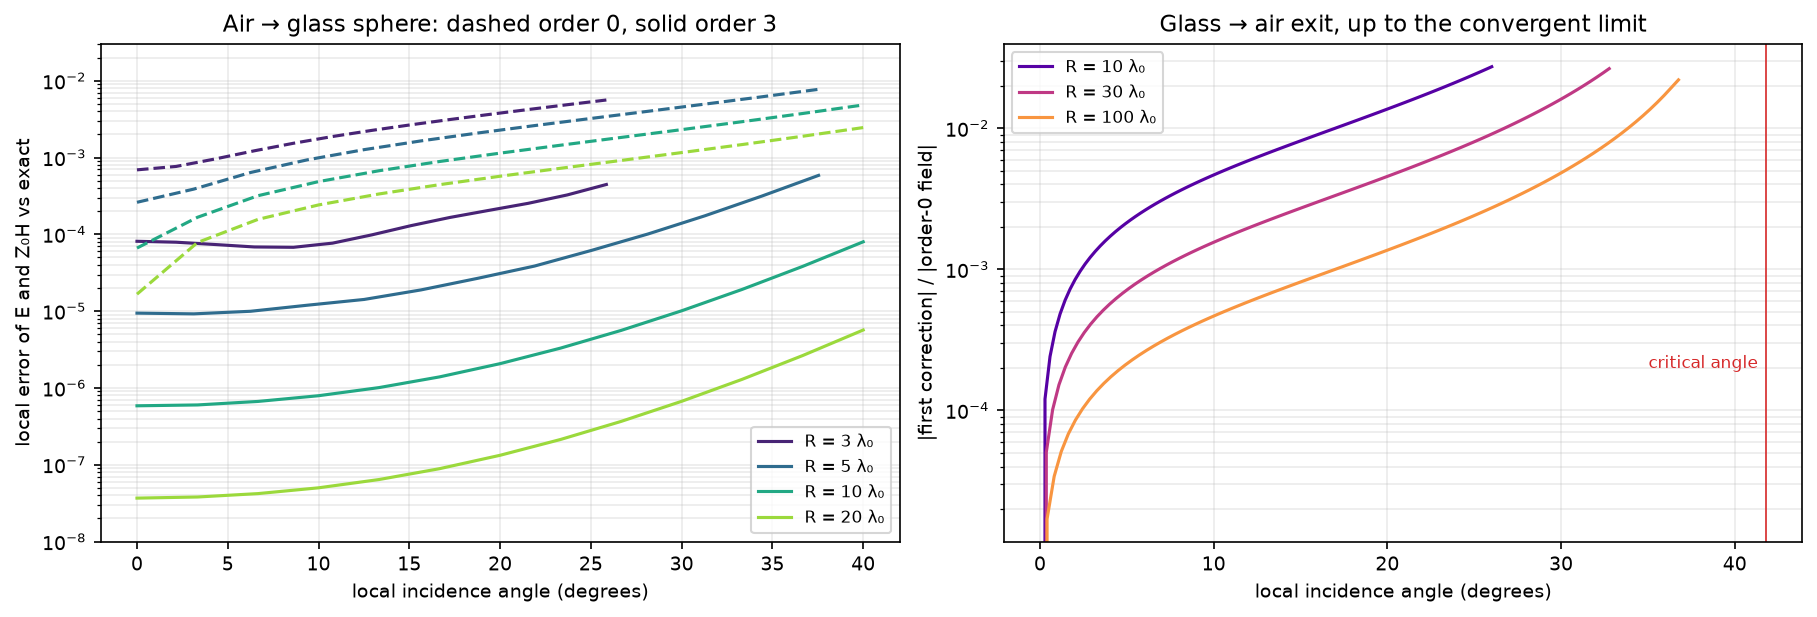

Sphere radius R (λ₀),Largest incidence shown (degrees),"Local error at that angle, order 0","Local error at that angle, order 3","Error reduction, order 0 → order 3"
3,25.9,5.62e-03,4.46e-04,13×
5,37.5,7.73e-03,5.86e-04,13×
10,40.0,4.84e-03,8.00e-05,60×
20,40.0,2.46e-03,5.68e-06,432×


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
radii = (3, 5, 10, 20)
shades = plt.cm.viridis(np.linspace(0.1, 0.85, len(radii)))
surface_rows = []
for radius, color in zip(radii, shades):
    limit = convergent_incidence(radius, 1.0, 1.0, 1.5, 3, curvature=-1)
    theta = np.radians(np.linspace(0, min(40.0, np.degrees(limit)), 13))
    uv = np.column_stack((np.sin(theta), 0 * theta))
    local = interface_expansion(
        lambda u, v: 1 - (1 - u * u - v * v) ** 0.5,
        uv * radius,
        n_incident=1.0,
        n_transmitted=1.5,
        direction=(0, 0, 1),
        amplitude=(1, 0, 0),
        order=3,
        length_scale=radius,
    )
    e, h = sphere_single_interface(local.points, 1.0, radius, 1.0, 1.5)["transmitted"]
    scale = np.sum(abs(e) ** 2 + abs(Z0 * h) ** 2, -1)
    errors = {}
    for n in (0, 3):
        t = local.trace("transmitted", 1.0, order=n)
        errors[n] = np.sqrt(
            np.sum(
                abs(t.electric.values - e) ** 2 + abs(Z0 * (t.magnetic - h)) ** 2, -1
            )
            / scale
        )
    angle = np.degrees(theta)
    axes[0].semilogy(angle, errors[0], "--", color=color)
    axes[0].semilogy(angle, errors[3], "-", color=color, label=f"R = {radius} λ₀")
    surface_rows.append(
        dict(
            R=radius,
            angle=angle[-1],
            e0=errors[0][-1],
            e3=errors[3][-1],
            gain=errors[0][-1] / errors[3][-1],
        )
    )
axes[0].set(
    xlabel="local incidence angle (degrees)",
    ylim=(1e-8, 3e-2),
    ylabel="local error of E and Z₀H vs exact",
    title="Air → glass sphere: dashed order 0, solid order 3",
)
axes[0].grid(True, which="both", alpha=0.25)
axes[0].legend(fontsize=8)

# Size of the first correction at a glass -> air exit: the order-0 error.
for radius, color in zip((10, 30, 100), plt.cm.plasma(np.linspace(0.15, 0.75, 3))):
    limit = convergent_incidence(radius, 1.0, 1.5, 1.0, 3, curvature=1)
    theta = np.linspace(0, limit, 91)
    values = canonical_values(radius, 1.0, 1.5, 1.0, theta, 3, 1)[2]  # transmitted
    order0 = np.abs(values[0, 0]).max(axis=(0, 1))
    first = np.abs(values[1, 0] - values[0, 0]).max(axis=(0, 1))
    axes[1].semilogy(
        np.degrees(theta), first / order0, color=color, label=f"R = {radius} λ₀"
    )
axes[1].axvline(np.degrees(np.arcsin(1 / 1.5)), color="tab:red", lw=0.8)
axes[1].text(
    np.degrees(np.arcsin(1 / 1.5)) - 0.5,
    2e-4,
    "critical angle",
    color="tab:red",
    fontsize=8,
    ha="right",
)
axes[1].set(
    xlabel="local incidence angle (degrees)",
    ylabel="|first correction| / |order-0 field|",
    title="Glass → air exit, up to the convergent limit",
)
axes[1].grid(True, which="both", alpha=0.25)
axes[1].legend(fontsize=8)
plt.show()
table(
    surface_rows,
    [
        ("R", "Sphere radius R (λ₀)", "{:g}"),
        ("angle", "Largest incidence shown (degrees)", "{:.1f}"),
        ("e0", "Local error at that angle, order 0", "{:.2e}"),
        ("e3", "Local error at that angle, order 3", "{:.2e}"),
        ("gain", "Error reduction, order 0 → order 3", "{:.0f}×"),
    ],
)

At the surface, order 3 reduces the order-0 error 13-fold at the steepest
convergent angle for R = 3–5λ₀, and several hundredfold for R = 20λ₀. At a glass → air exit the first
correction grows steeply toward the critical angle and reaches 2–3% of the
field before the series stops converging: there, order 0 alone is visibly
wrong at the surface.

The next experiment shows what reaches a focus when rays meet an exit near that
limit. A plane wave inside glass, tilted by an increasing angle, leaves through a
spherical exit (R = 30λ₀, clear radius 12λ₀, with a stop at the edge). The
tilt raises the steepest local incidence from 24° to 44°; beyond the convergent
limit (32.8°) the interaction falls back to order 0. There is no full-wave
reference at this size, so this measures only how much order 3 changes the
propagated field.

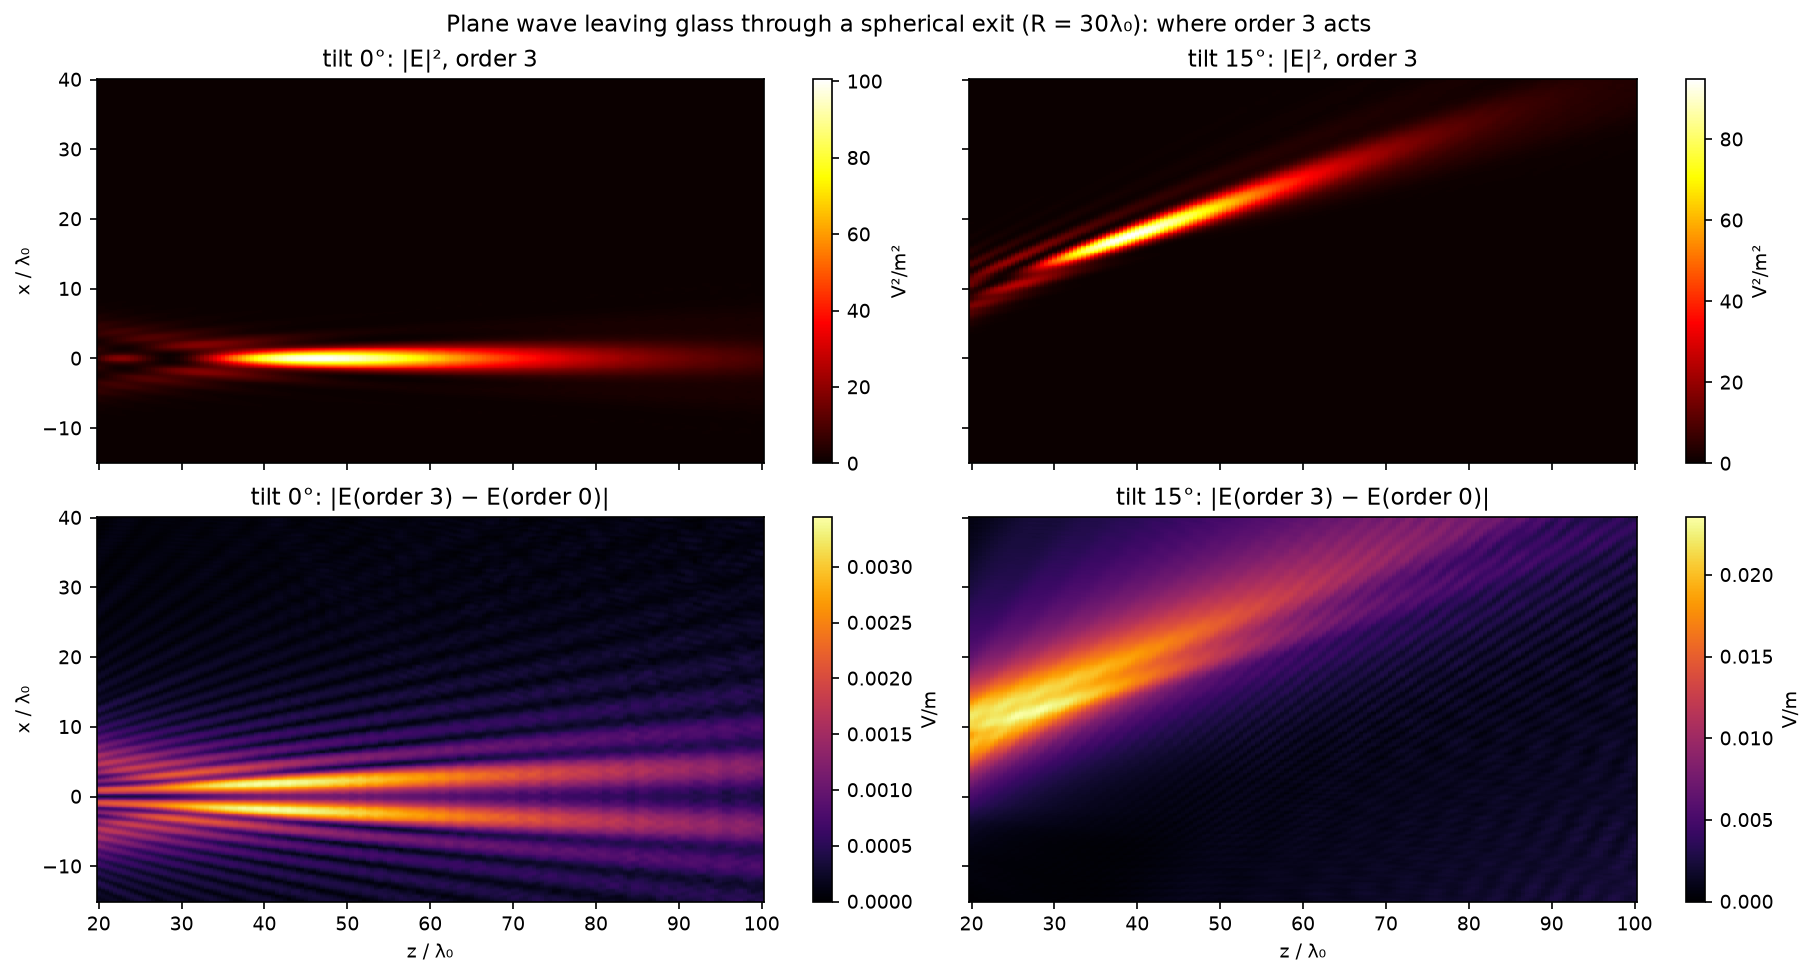

Beam tilt in the glass (degrees),Steepest local incidence at the exit (degrees),"Change of the propagated field, order 0 → 3 (relative L2)",Largest local change / largest |E|
0,24,5.1e-04,3.4e-04
10,34,1.9e-03,1.1e-03
15,39,4.0e-03,2.4e-03
20,44,4.6e-03,2.9e-03


In [16]:
glass = optics.HomogeneousRegion("glass", optics.Dielectric(1.5))
air = optics.HomogeneousRegion("air", optics.Dielectric(1.0))
radius, aperture = 30.0, 12.0
exit_face = optics.OpticalSystem(
    (optics.DielectricInterface(optics.SphericalCap(-radius), glass, air),),
    (aperture,),
    (aperture,),
)
lattice = (np.arange(256) - 128) * 96 / 256
grid = optics.CartesianGrid(lattice, lattice)
xs = np.linspace(-15, 40, 441)
zs = np.linspace(20, 100, 161)
zz, xx = np.meshgrid(zs, xs)
plane = optics.PointGrid(np.stack((xx, 0 * xx, zz), -1))
tilt_rows, tilt_maps = [], {}
k = 2 * np.pi * 1.5
for tilt in (0, 10, 15, 20):
    t = np.radians(tilt)
    source = optics.PlaneWaveExpansion(
        [k * np.array([np.sin(t), 0, np.cos(t)])],
        [[np.cos(t), 0, -np.sin(t)]],
        [0, 0, 0],
        1.0,
        glass,
    )
    fields = {}
    for n in (0, 3):
        solution = study.propagate_high_frequency(
            source,
            exit_face,
            grid,
            max_sine=0.92,
            interaction=study.OrderInteraction(n),
        )
        fields[n] = solution.evaluate(plane, backend="nufft").electric.values
    tilt_maps[tilt] = fields
    change = np.linalg.norm(fields[3] - fields[0]) / np.linalg.norm(fields[0])
    tilt_rows.append(
        dict(
            tilt=tilt,
            steepest=tilt + np.degrees(np.arcsin(aperture / radius)),
            change=change,
            local=np.max(np.linalg.norm(fields[3] - fields[0], axis=-1))
            / np.max(np.linalg.norm(fields[0], axis=-1)),
        )
    )
fig, axes = plt.subplots(
    2, 2, figsize=(12, 6.4), sharex=True, sharey=True, layout="constrained"
)
for column, tilt in enumerate((0, 15)):
    e0, e3 = tilt_maps[tilt][0], tilt_maps[tilt][3]
    for row, (values, title, unit, cmap) in enumerate(
        (
            (np.sum(abs(e3) ** 2, -1), f"tilt {tilt}°: |E|², order 3", "V²/m²", "hot"),
            (
                np.linalg.norm(e3 - e0, axis=-1),
                f"tilt {tilt}°: |E(order 3) − E(order 0)|",
                "V/m",
                "inferno",
            ),
        )
    ):
        ax = axes[row, column]
        im = ax.pcolormesh(
            zs,
            xs,
            values,
            cmap=cmap,
            shading="nearest",
            norm=Normalize(0, float(values.max())),
        )
        ax.set(
            title=title,
            xlabel="z / λ₀" if row else None,
            ylabel="x / λ₀" if not column else None,
        )
        fig.colorbar(im, ax=ax, label=unit)
fig.suptitle(
    "Plane wave leaving glass through a spherical exit (R = 30λ₀): where order 3 acts"
)
plt.show()
table(
    tilt_rows,
    [
        ("tilt", "Beam tilt in the glass (degrees)", "{:g}"),
        ("steepest", "Steepest local incidence at the exit (degrees)", "{:.0f}"),
        (
            "change",
            "Change of the propagated field, order 0 → 3 (relative L2)",
            "{:.1e}",
        ),
        ("local", "Largest local change / largest |E|", "{:.1e}"),
    ],
)

The propagated effect grows as the steepest rays approach the critical angle,
but stays below about one per cent: the rays that need the correction carry a
small share of the light, and past the convergent limit no correction applies.
For single-pass imaging, order 0 is therefore an excellent approximation in the
regime where the series is usable. The corrections become essential when an
application needs the local field at the surface to better than about 10⁻³, or
when local errors are repeated, as in the resonator below.

## 9 · A sphere under a beam wider than itself: Lorenz–Mie and ours, on the whole plane

A glass sphere (n = 1.5, radius 5λ₀) under a Gaussian beam slightly wider than
itself (w₀ = 6λ₀, waist at the centre). Light travels upward. Each row shares
one linear scale of |E|:

- **incident:** the beam alone;
- **scattered:** what the sphere radiates, including the part behind it that
  cancels the beam and forms the shadow;
- **total:** incident plus scattered outside, the interior field inside.

**Top row, Lorenz–Mie.** The exact field is evaluated with beam-shape
coefficients (`references.axial_beam`): this beam contains only the multipoles
m = ±1, so each point costs one sum over n.

**Rows 2 and 3, ours, order 0 and order 3.** Only our operators are used:
the interaction of every plane wave at every surface point (T and R, with the
curvature corrections at order 3), Q⁻¹ and the exact homogeneous step (ASM).

- *The sphere.* The beam meets the whole surface. Waves arriving at a point
  are transmitted and reflected; waves leaving it outward are blocked, which
  is the shadow (−incident), continuous with the grazing reflection
  (r → −1). The transmitted trace is fitted (Q⁻¹) by plane waves in all
  directions inside the sphere, each matched where it leaves the surface
  inward, and meets the whole surface again, where what it transmits leaves.
- *The field outside, through intermediate surfaces.* Q carries a field
  between a surface and a plane. To reach the space beside the sphere the
  transport is made continuous: the intermediate surface S_t is the plane
  z = t outside the sphere joined to the part of the sphere beyond it, and
  runs from the sphere to a plane as t crosses it. From S_t to S_{t+dt}
  the plane part moves by the exact ASM step; next to the surface, in a band
  from λ₀/4 inside to λ₀/7 outside, every outgoing wave of the interaction is
  carried from its surface point along its own wavevector. Light going up is
  marched upward and light going down downward. The planes are the rows of
  the picture, so the plane is filled everywhere
  (`experiments.intermediate`).

Included here: the external reflection and shadow (pass 0) and the light that
entered once (pass 1). The later internal returns are not yet included.

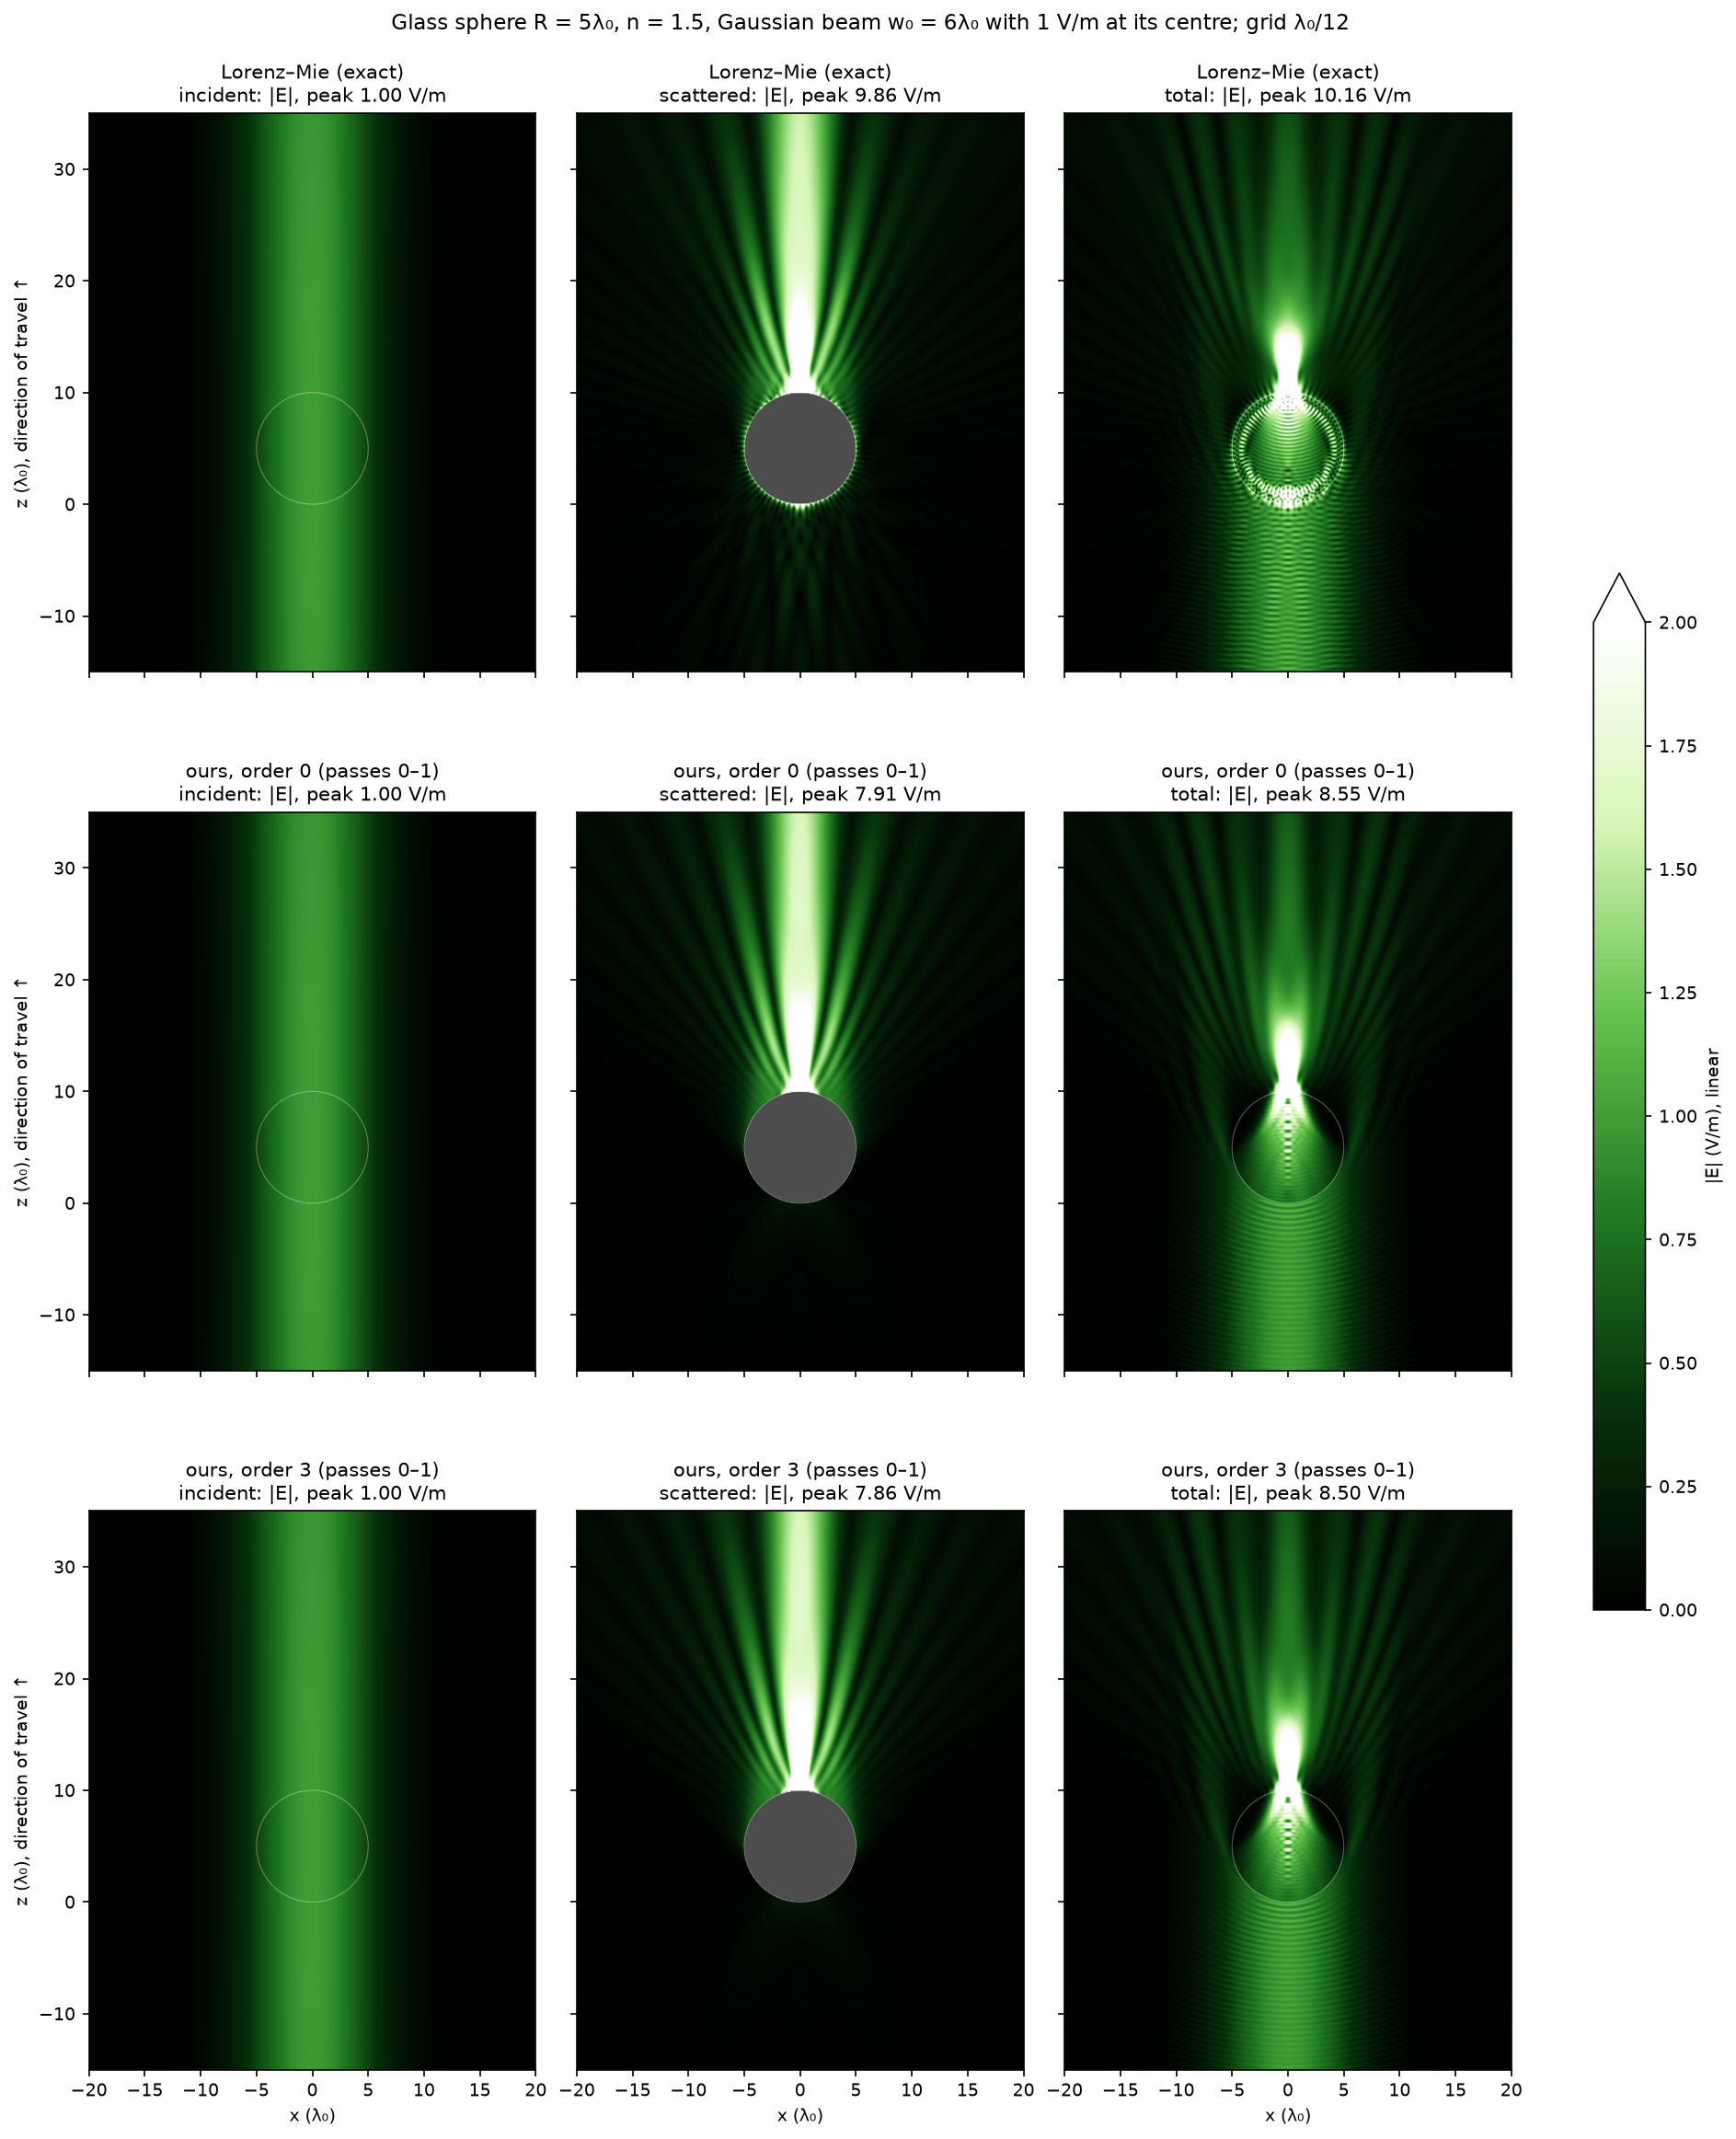

Interface order,Run time of ours (s),Plane-wave directions inside the sphere,Surface sample points,Relative residual of the Q⁻¹ fit of the entering light
0,837,7000,11518,1.6e-02
3,967,7000,11518,1.6e-02


In [17]:
from matplotlib.colors import LinearSegmentedColormap

# One hue, black to white through green (the 532 nm of these runs).
GREEN = LinearSegmentedColormap.from_list(
    "green", ["#000000", "#06300a", "#1f7a22", "#62c24a", "#d9f7b8", "#ffffff"]
)
picture, picture_info = study.mie_picture()
rows = [("Lorenz–Mie (exact)", picture)]
ours_info = {}
for order in (0, 3):
    data, ours_info[order] = study.sphere_ours(order)
    rows.append((f"ours, order {order} (passes 0–{ours_info[order]['passes']})", data))
px, pz, radius = picture["x"], picture["z"], picture_info["radius"]
pxx, pzz = np.meshgrid(px, pz)
interior = np.hypot(pxx, pzz - radius) <= radius
ceiling = 2.0  # V/m; the colour saturates above it (the jet reaches the peak given)
fig, axes = plt.subplots(
    3, 3, figsize=(12.5, 15.5), sharex=True, sharey=True, layout="constrained"
)
for i, (label, data) in enumerate(rows):
    for j, name in enumerate(("incident", "scattered", "total")):
        ax = axes[i, j]
        # The scattered field is defined outside the sphere only (grey inside).
        image = (
            np.where(interior, np.nan, data[name])
            if name == "scattered"
            else data[name]
        )
        ax.set_facecolor("0.3")
        im = ax.imshow(
            image,
            origin="lower",
            cmap=GREEN,
            vmin=0,
            vmax=ceiling,
            extent=[px[0], px[-1], pz[0], pz[-1]],
            interpolation="bilinear",
        )
        ax.add_patch(
            plt.Circle(
                (0, radius), radius, fill=False, color="white", lw=0.5, alpha=0.35
            )
        )
        ax.set_title(
            f"{label}\n{name}: |E|, peak {float(np.nanmax(image)):.2f} V/m", fontsize=10
        )
        if i == 2:
            ax.set_xlabel("x (λ₀)")
        if j == 0:
            ax.set_ylabel("z (λ₀), direction of travel ↑")
fig.colorbar(im, ax=axes, shrink=0.5, extend="max", label="|E| (V/m), linear")
fig.suptitle(
    f"Glass sphere R = {radius:g}λ₀, n = {study.INDEX}, Gaussian beam w₀ = "
    f"{picture_info['waist']:g}λ₀ with 1 V/m at its centre; grid λ₀/{1 / picture_info['step']:.0f}"
)
plt.show()
table(
    [
        dict(
            order=order,
            seconds=info["seconds"],
            directions=info["directions"],
            samples=info["surface_samples"],
            fit=info["fit_residuals"][0],
        )
        for order, info in ours_info.items()
    ],
    [
        ("order", "Interface order", "{}"),
        ("seconds", "Run time of ours (s)", "{:.0f}"),
        ("directions", "Plane-wave directions inside the sphere", "{}"),
        ("samples", "Surface sample points", "{}"),
        ("fit", "Relative residual of the Q⁻¹ fit of the entering light", "{:.1e}"),
    ],
)

**Reading the picture.**

- Our field fills the whole plane, with no blank region, and reproduces the
  jet behind the sphere, the fans of wide-angle radiation, the shadow and the
  standing waves in front of the sphere (incident against the reflection).
- Orders 0 and 3 are nearly indistinguishable at this scale: the corrections
  change the local surface field, not the picture.
- The bright ring just inside the surface of the Mie field is missing from
  ours. At exactly R = 5λ₀ the sphere sits on a whispering-gallery resonance:
  partial waves n = 35–37, beyond the geometric edge (kR = 31.4), carry about
  64 % of the interior field and 17 % of the scattered field. The beam excites
  them by tunnelling, which a local interaction cannot do. At R = 4.97λ₀ or
  5.03λ₀ their share of the interior falls to about 8–15 %.
- The later internal returns (passes 2 and beyond) are not yet included; they
  account for part of the lower peak of our scattered field and for faint
  structure outside.

## 10 · Repeated encounters: where higher orders accumulate

A single pass meets each surface once, so a small local error stays small. In a
resonator, light meets the same curved surfaces many times and local errors add
coherently. The saved periodic-cavity study (index 3, weakly corrugated faces;
[curvature_layer.py](../../examples/curvature_layer.py)) shows this: with P
round trips, the error of the internal field against an independent
Fourier–Maxwell solution.

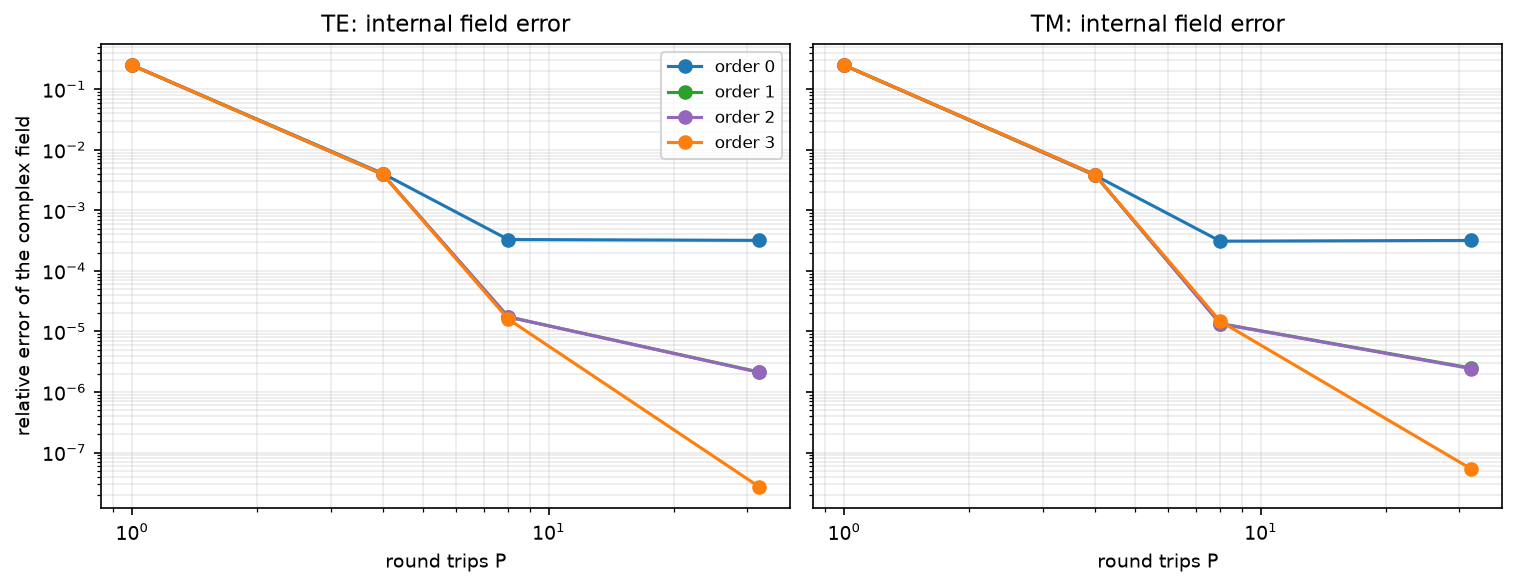

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True, layout="constrained")
for ax, polarization in zip(axes, ("TE", "TM")):
    saved = json.loads(
        (ROOT / f"output/curvature_validation/layer_{polarization}_7.json").read_text()
    )
    for n in range(4):
        rows_n = sorted(
            (r for r in saved["rows"] if r["order"] == n), key=lambda r: r["pairs"]
        )
        ax.loglog(
            [r["pairs"] for r in rows_n],
            [r["complex_E"] for r in rows_n],
            "o-",
            color=ORDER_COLORS[n],
            label=f"order {n}",
        )
    ax.set(
        xlabel="round trips P",
        title=f"{polarization}: internal field error",
        ylabel="relative error of the complex field" if polarization == "TE" else None,
    )
    ax.grid(True, which="both", alpha=0.25)
axes[0].legend(fontsize=8)
plt.show()

With enough round trips the order-0 error stops improving near 3·10⁻⁴, while
order 3 continues to about 3·10⁻⁸: four orders of magnitude. Orders 1 and 2
nearly coincide here (the order-1 curve lies under order 2): for this weak,
nearly symmetric corrugation the second-order term is very small. With a single
pass, P = 1, missing returns leave 25% error whatever the order.

## 11 · Summary

In [19]:
lines = []
for name in study.MAIN:
    m = lens_results[name][0]["metrics"]
    lines.append(
        f"- **{name}:** order 3 changes our axial field by {m['axial change N=0 to N=3']:.1e}; "
        f"BEM itself changes by {m['BEM refinement change']:.1e} between element sizes; "
        f"our error against BEM is {m['Ours N=0 axial error vs BEM λ/4']:.1%} at order 0 and "
        f"{m['Ours N=3 axial error vs BEM λ/4']:.1%} at order 3. Stratton–Chu agrees with our "
        f"propagation to {m['Stratton–Chu vs Q^-1 N=3']:.1e}."
    )
display(Markdown("\n".join(lines)))
print(f"notebook run time: {perf_counter() - started:.0f} s")

- **thin plano-convex:** order 3 changes our axial field by 2.2e-04; BEM itself changes by 1.0e-02 between element sizes; our error against BEM is 3.5% at order 0 and 3.5% at order 3. Stratton–Chu agrees with our propagation to 1.8e-02.
- **thin convex-plano:** order 3 changes our axial field by 1.9e-04; BEM itself changes by 7.2e-03 between element sizes; our error against BEM is 3.5% at order 0 and 3.5% at order 3. Stratton–Chu agrees with our propagation to 2.5e-02.
- **thin biconvex:** order 3 changes our axial field by 1.1e-04; BEM itself changes by 7.1e-03 between element sizes; our error against BEM is 3.6% at order 0 and 3.6% at order 3. Stratton–Chu agrees with our propagation to 2.1e-02.
- **thin asymmetric biconvex:** order 3 changes our axial field by 1.3e-04; BEM itself changes by 9.4e-03 between element sizes; our error against BEM is 3.3% at order 0 and 3.3% at order 3. Stratton–Chu agrees with our propagation to 1.9e-02.

notebook run time: 117 s


**What the notebook shows**

1. The curvature expansion is correct: orders 0–3 converge to exact curved-interface
   fields at the predicted rate, for both polarizations and both curvature signs.
2. It applies over a limited angular range, set by series convergence. The range is
   narrow for glass → air exits and for small radii; outside it the interaction
   stays at order 0.
3. Our single-pass lens model is reliable when the element Fresnel number
   a²/(λ₀T) is large. Thin 6λ₀ lenses agree with BEM to a few per cent, close to
   BEM's own refinement change; thick lenses of the same size are 40–50% off,
   whatever the curvature order. That gap is a thickness effect near the rim, not
   a curvature or propagation error.
4. On the thin lenses, order 3 reduces the exit-face magnetic jump about thirtyfold,
   but changes the propagated field only by a few parts in 10⁴, far below the
   remaining difference from BEM. For single lenses of this size, order 0 is
   sufficient.
5. Stratton–Chu radiation of our exit field agrees with our own surface-to-plane
   propagation to about 2%, part of which is the truncated radiating surface.
6. Order 3 matters for the local field at a curved surface: it removes the
   order-0 error by one to three orders of magnitude, and near a glass → air
   critical angle that error reaches 2–3%. Even there, the effect on
   a single-pass focus stays below about one per cent.
7. Under a beam wider than a sphere (section 9), our field, carried through
   intermediate surfaces, fills the whole plane and reproduces the jet, the
   fans, the shadow and the standing waves of Lorenz–Mie from the first
   pass. Missing are a whispering-gallery resonance excited by tunnelling at
   R = 5λ₀, and the later internal returns.
8. Higher orders pay off most where local errors accumulate over many
   encounters, as in the resonator of section 10.